# Decision Trees and Random Forests - Machine Learning with Python

The following topics are covered in this tutorial:

- Downloading a real-world dataset
- Preparing a dataset for training
- Training and interpreting decision trees
- Training and interpreting random forests
- Overfitting, hyperparameter tuning & regularization
- Making predictions on single inputs


## Problem Statement

This tutorial takes a practical and coding-focused approach. We'll learn how to use _decision trees_ and _random forests_ to solve a real-world problem from [Kaggle](https://kaggle.com/datasets):

> **QUESTION**: The [Rain in Australia dataset](https://kaggle.com/jsphyg/weather-dataset-rattle-package) contains about 10 years of daily weather observations from numerous Australian weather stations. Here's a small sample from the dataset:
> 
> ![](https://i.imgur.com/5QNJvir.png)
>
> As a data scientist at the Bureau of Meteorology, you are tasked with creating a fully-automated system that can use today's weather data for a given location to predict whether it will rain at the location tomorrow. 
>
>
> ![](https://i.imgur.com/KWfcpcO.png)

In [1]:
import opendatasets as od
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib
import os
%matplotlib inline

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 150)
sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (10, 6)
matplotlib.rcParams['figure.facecolor'] = '#00000000'

In [2]:
import pandas as pd

raw_df = pd.read_csv(
    r"C:\Users\Rohaan farooq\Desktop\PythonLab\Decision-Trees-and-Random-Forests\weather-dataset-rattle-package\weatherAUS.csv"
)

raw_df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


Each row shows the measurements for a given date at a given location. The last column "RainTomorrow" contains the value to be predicted.

Let's check the column types of the dataset.

In [3]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null



Let's drop any rows where the value of the target column `RainTomorrow` in empty.

In [4]:
raw_df.dropna(subset=['RainTomorrow'] , inplace = True)

1. Check the target distribution
First, see how many days have rain tomorrow versus no rain.

In [5]:
raw_df['RainTomorrow'].value_counts()

RainTomorrow
No     110316
Yes     31877
Name: count, dtype: int64

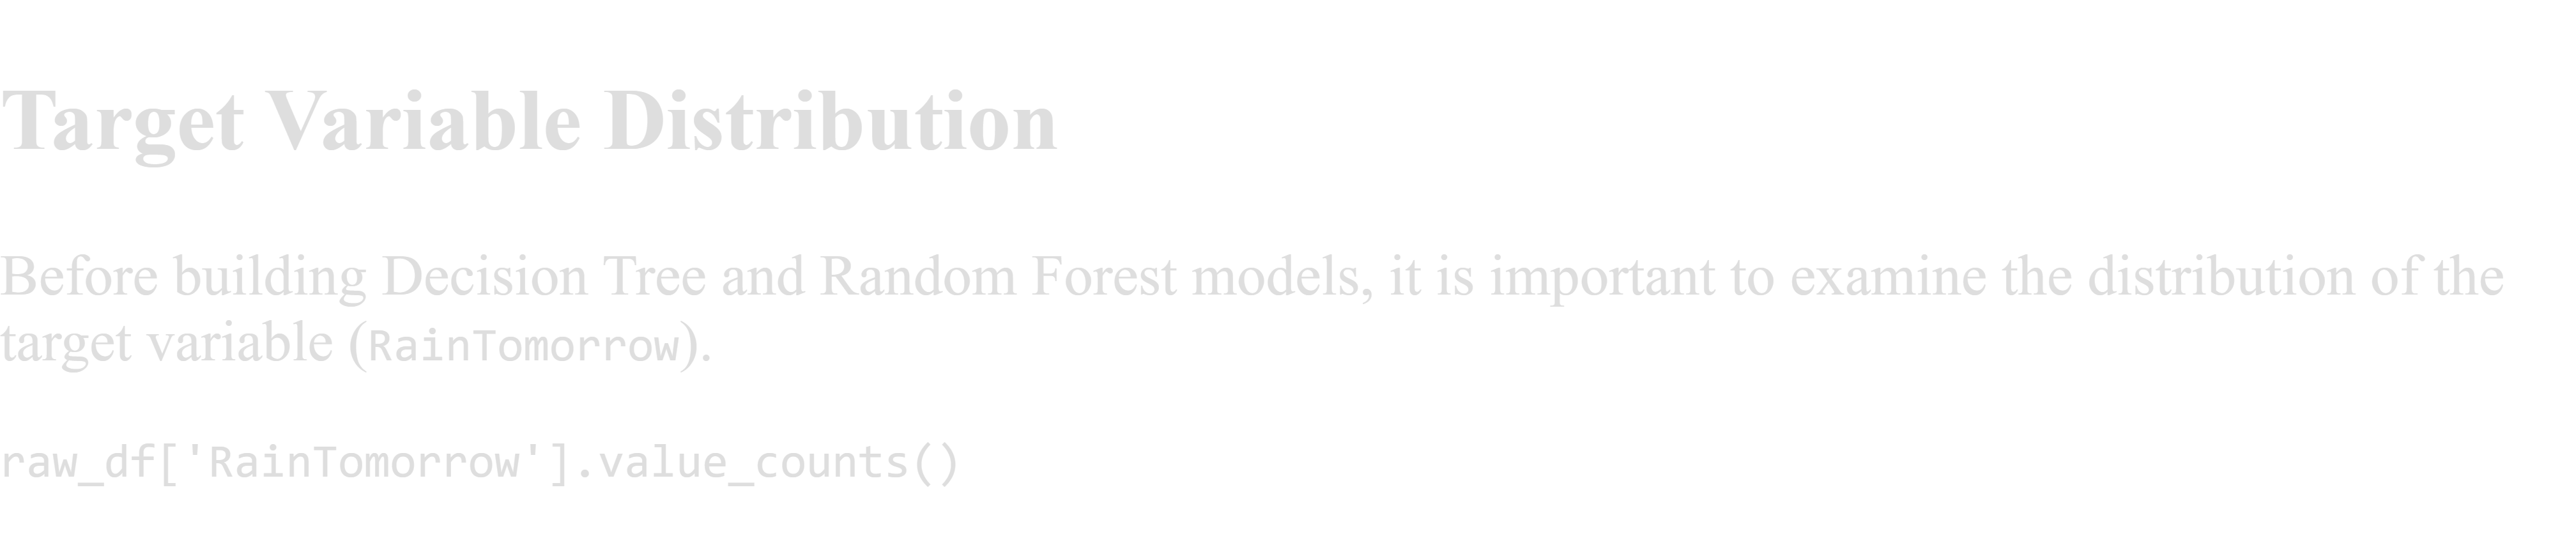

In [6]:
raw_df['RainTomorrow'].value_counts(normalize = True) * 100

RainTomorrow
No     77.581878
Yes    22.418122
Name: proportion, dtype: float64

##### Visualize the distribution:

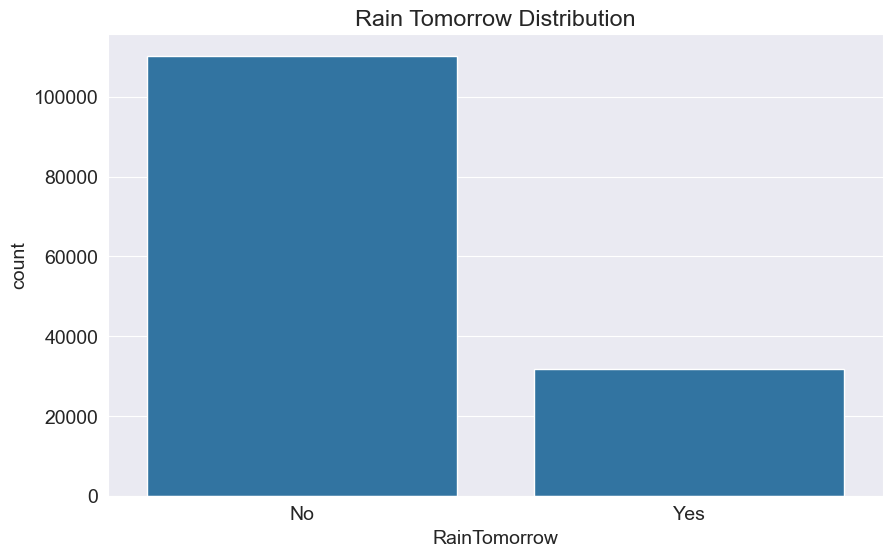

In [7]:
sns.countplot(data=raw_df , x='RainTomorrow')
plt.title('Rain Tomorrow Distribution')
plt.show()

- What to observe: Is the dataset balanced, or are there significantly more days without rain?
2. Explore numerical columns
Calculate summary statistics for temperature, rainfall, humidity, pressure, wind speed, and other numerical features.

In [8]:
raw_df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,141556.000000,141871.000000,140787.000000,81350.000000,74377.000000,132923.000000,140845.000000,139563.000000,140419.000000,138583.000000,128179.000000,128212.000000,88536.000000,85099.000000,141289.000000,139467.000000
mean,12.186400,23.226784,2.349974,5.469824,7.624853,39.984292,14.001988,18.637576,68.843810,51.482606,1017.653758,1015.258204,4.437189,4.503167,16.987509,21.687235
std,6.403283,7.117618,8.465173,4.188537,3.781525,13.588801,8.893337,8.803345,19.051293,20.797772,7.105476,7.036677,2.887016,2.720633,6.492838,6.937594
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.500000,977.100000,0.000000,0.000000,-7.200000,-5.400000
25%,7.600000,17.900000,0.000000,2.600000,4.900000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.900000,1010.400000,1.000000,2.000000,12.300000,16.600000
50%,12.000000,22.600000,0.000000,4.800000,8.500000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.600000,1015.200000,5.000000,5.000000,16.700000,21.100000
75%,16.800000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.400000,1020.000000,7.000000,7.000000,21.600000,26.400000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.000000,1039.600000,9.000000,9.000000,40.200000,46.700000


In [9]:
raw_df.groupby('RainTomorrow')[ ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity9am',
     'Humidity3pm', 'Pressure9am', 'Pressure3pm',
     'WindGustSpeed', 'WindSpeed3pm', 'Sunshine']].mean()

,MinTemp,MaxTemp,Rainfall,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,WindGustSpeed,WindSpeed3pm,Sunshine
RainTomorrow,,,,,,,,,,
No,11.897675,23.836247,1.270290,66.217573,46.510625,1018.595599,1016.113587,38.288391,18.222804,8.546358
Yes,13.186890,21.119100,6.142104,77.983314,68.800019,1014.400000,1012.300820,45.946764,20.078509,4.471761


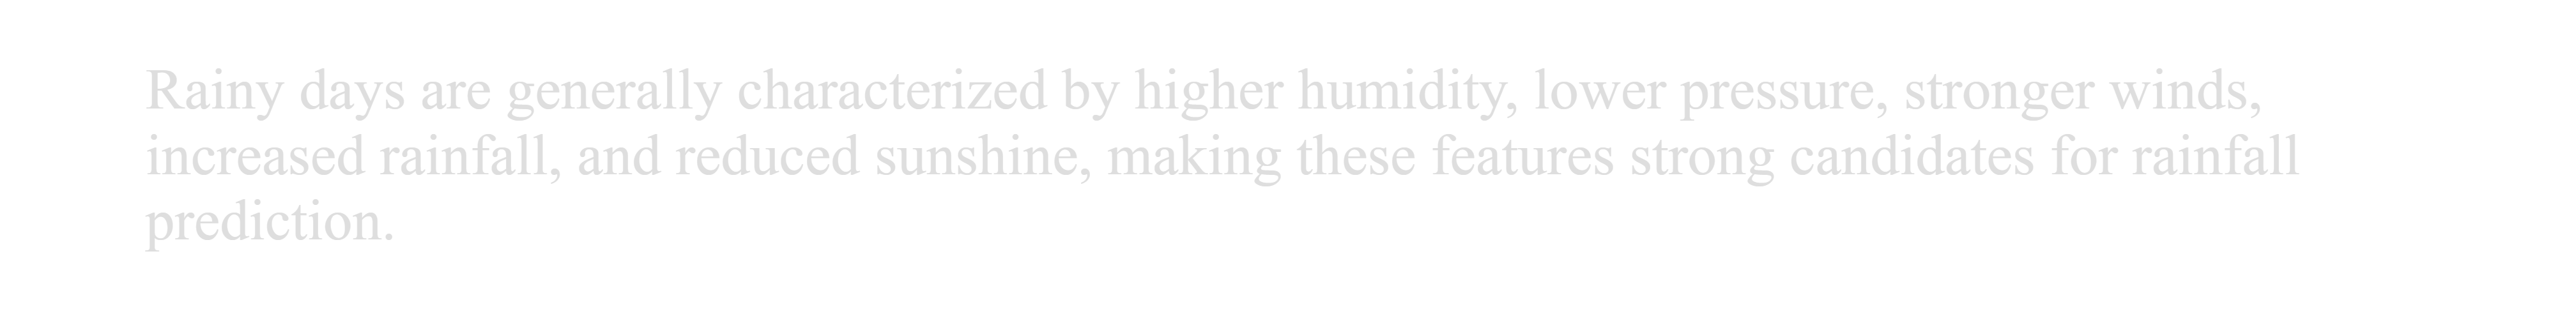

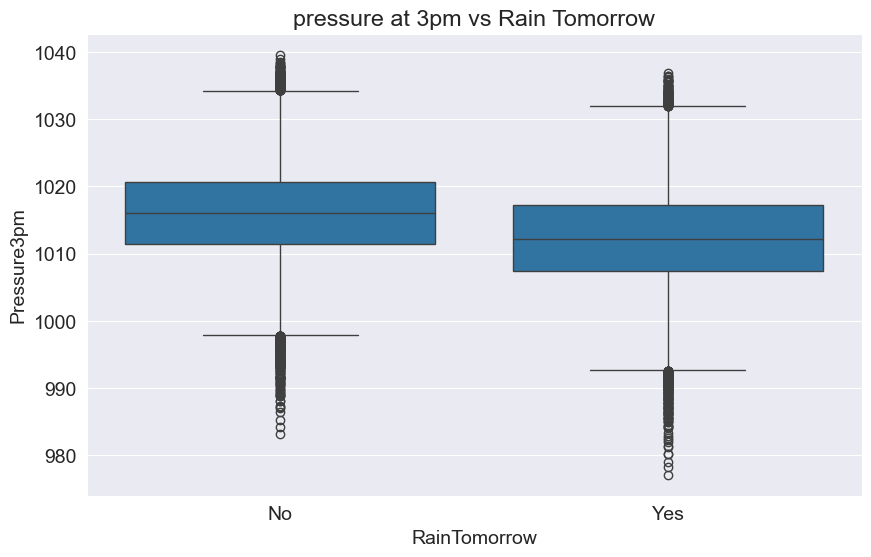

In [10]:
sns.boxplot(data = raw_df , x='RainTomorrow' , y = 'Pressure3pm')
plt.title('pressure at 3pm vs Rain Tomorrow')
plt.show()

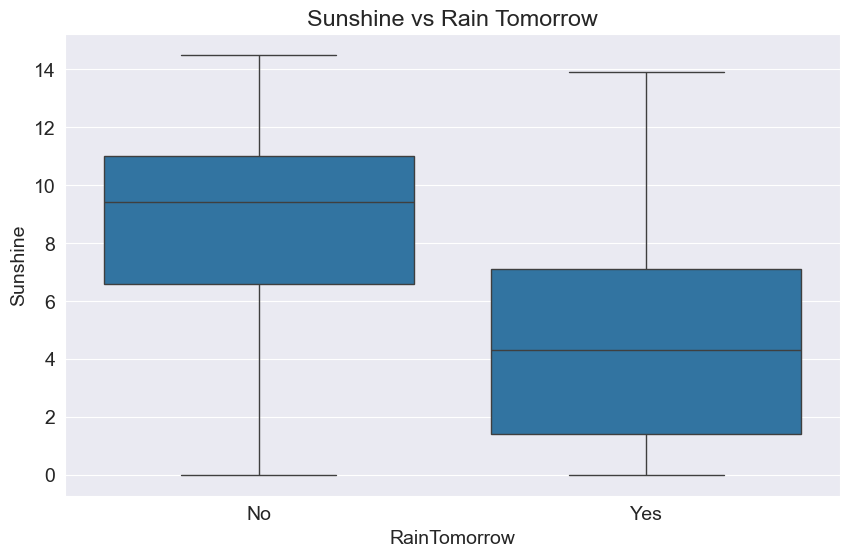

In [11]:
sns.boxplot(data=raw_df, x='RainTomorrow', y='Sunshine')
plt.title('Sunshine vs Rain Tomorrow')
plt.show()

4. Explore categorical columns
Check how tomorrow's rain varies by today's rain and wind direction.

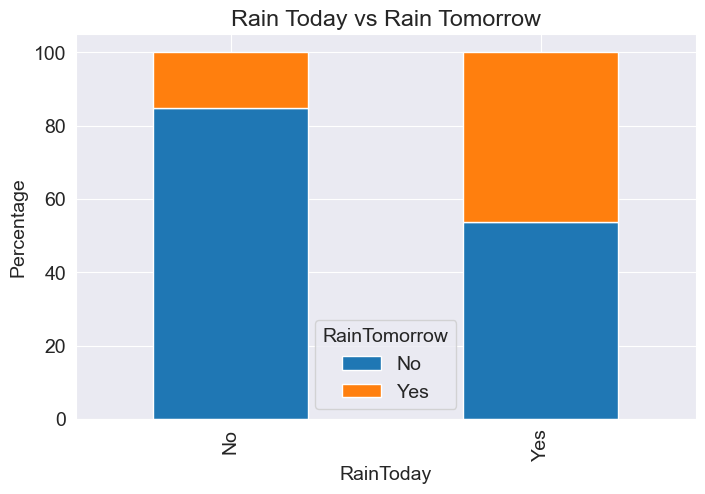

In [12]:
rain_transition = pd.crosstab(
    raw_df['RainToday'],
    raw_df['RainTomorrow'],
    normalize='index'
) * 100

rain_transition.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5),
)

plt.ylabel('Percentage')
plt.title('Rain Today vs Rain Tomorrow')
plt.show()

## Relationship Between Rain Today and Rain Tomorrow

To investigate whether today's rainfall influences tomorrow's rainfall, a cross-tabulation analysis was performed between the variables `RainToday` and `RainTomorrow`.

### Percentage Distribution

| Rain Today | No Rain Tomorrow | Rain Tomorrow |
|------------|-----------------|---------------|
| No | 84.81% | 15.19% |
| Yes | 53.59% | 46.41% |

### Observations

- When there is **no rainfall today**, the probability of rain tomorrow is only **15.19%**.
- When it **rains today**, the probability of rain tomorrow increases significantly to **46.41%**.
- Rainfall tomorrow is approximately **three times more likely** when rainfall is recorded today.
- Weather systems that produce rainfall often persist across consecutive days rather than occurring as isolated events.
- The difference between the two groups is substantial, suggesting a strong relationship between today's and tomorrow's rainfall.

### Key Insight

The variable `RainToday` appears to be one of the strongest indicators of future rainfall. Observations with rainfall today have a much higher probability of experiencing rainfall tomorrow compared to observations without rainfall today.

### Conclusion

The analysis demonstrates a clear dependency between today's and tomorrow's rainfall. This feature is expected to play an important role in rainfall prediction models such as Decision Trees and Random Forests.

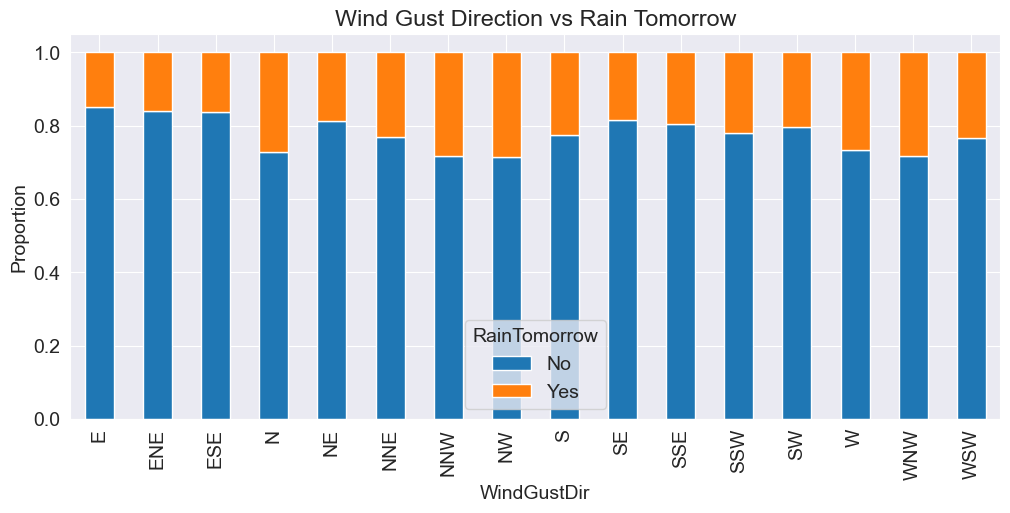

In [13]:
pd.crosstab(
    raw_df['WindGustDir'],
    raw_df['RainTomorrow'],
    normalize='index'
).plot(kind='bar', stacked=True, figsize=(12, 5))

plt.title('Wind Gust Direction vs Rain Tomorrow')
plt.ylabel('Proportion')
plt.show()

## Relationship Between Wind Gust Direction and Rain Tomorrow

To examine whether wind direction influences rainfall, the proportion of rainy and non-rainy observations was analyzed for each wind gust direction.

### Observations

- Across all wind directions, **No Rain** remains the majority outcome.
- Some wind directions exhibit noticeably higher proportions of rainfall than others.
- Wind directions such as **N**, **NNW**, **NW**, **W**, and **WNW** appear to have a higher proportion of rainy observations compared to directions such as **E**, **ENE**, and **ESE**.
- Eastern wind directions generally show lower rainfall proportions, with over 80% of observations belonging to the **No Rain** category.
- Several western and north-western wind directions exhibit rainfall proportions approaching 25% to 30%.

### Interpretation

- Wind direction may influence the movement of weather systems and moisture-bearing air masses.
- Certain wind directions appear to be associated with a greater likelihood of rainfall.
- Although wind direction alone is not sufficient to predict rainfall, it can provide useful information when combined with other meteorological variables such as humidity, pressure, temperature, and rainfall history.

### Conclusion

The distribution suggests that **WindGustDir** contains predictive information for rainfall forecasting. Some wind directions are associated with a higher probability of rain tomorrow, making this feature potentially valuable for Decision Tree and Random Forest models.

You can also investigate which locations have the highest proportion of rainy days:

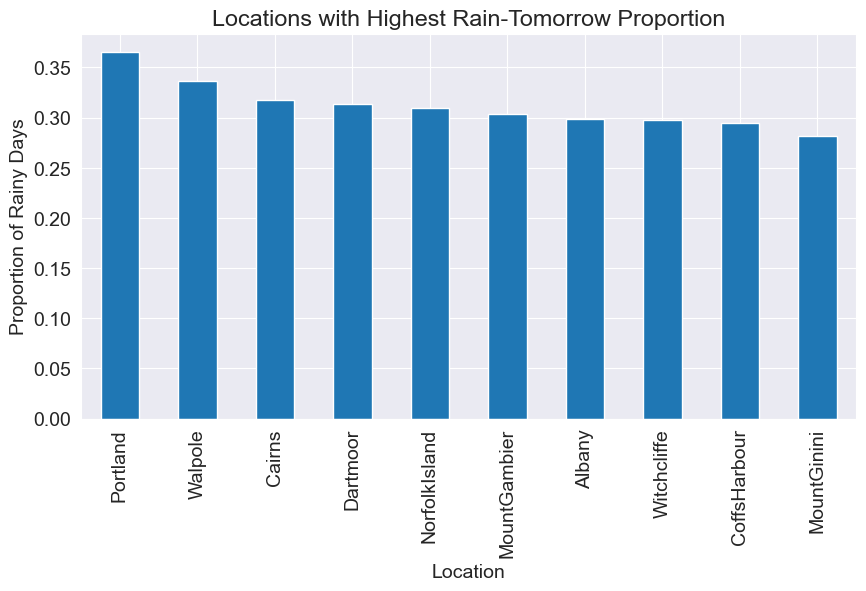

In [14]:
location_rain = pd.crosstab(raw_df['Location'] , raw_df['RainTomorrow'] , normalize='index')

location_rain = location_rain.sort_values('Yes' , ascending=False)
location_rain['Yes'].head(10).plot(kind='bar' , figsize=(10 , 5))
plt.title('Locations with Highest Rain-Tomorrow Proportion')
plt.ylabel('Proportion of Rainy Days')
plt.show()

> Rainfall occurrence varies significantly across locations, with Portland, Walpole, and Cairns showing the highest proportions of rainy days. This suggests that location is an important predictor for rainfall forecasting.

5. Examine correlations between numerical features

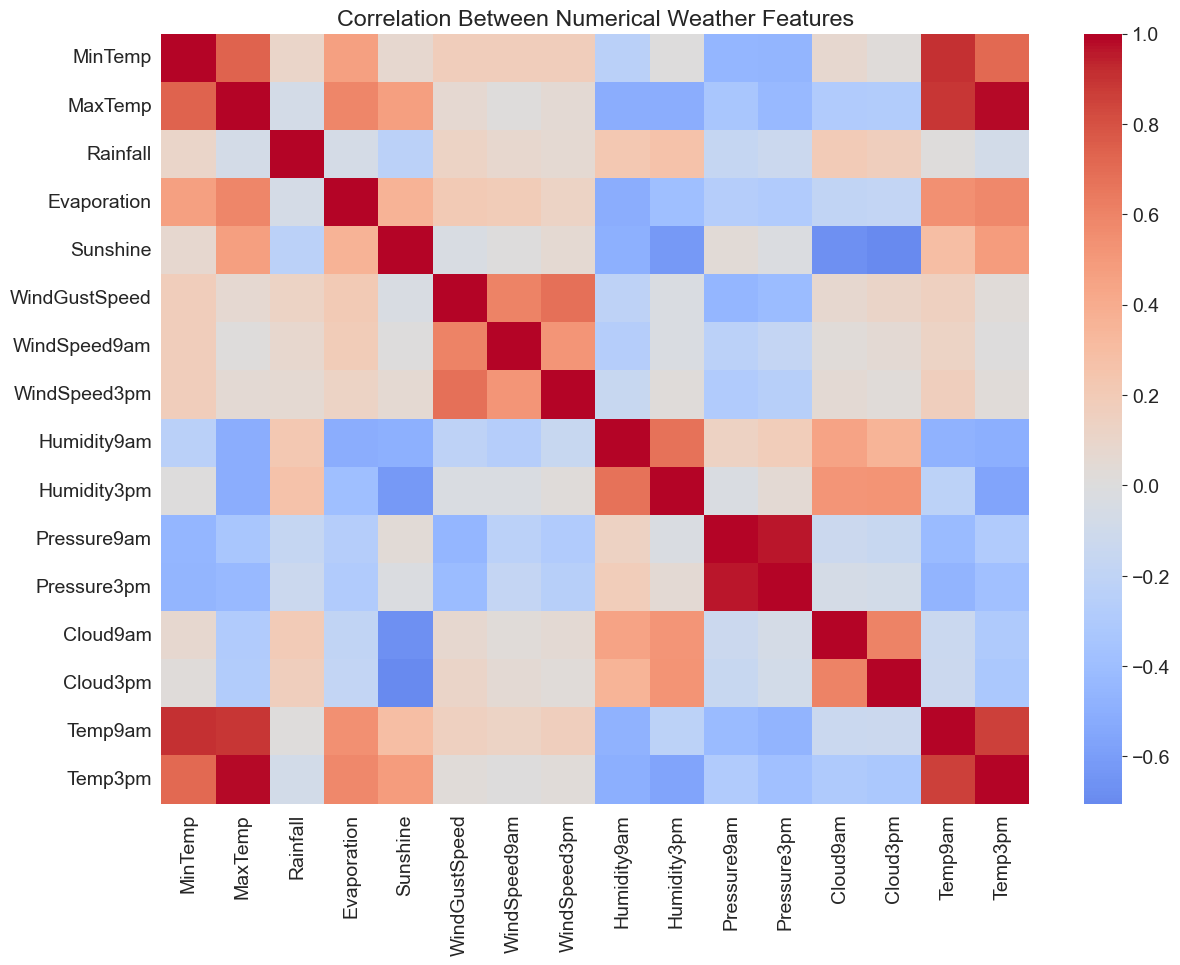

In [15]:
numeric_df = raw_df.select_dtypes(include='number')

plt.figure(figsize=(14, 10))
sns.heatmap(numeric_df.corr(), cmap='coolwarm', center=0)
plt.title('Correlation Between Numerical Weather Features')
plt.show()

## Correlation Analysis of Numerical Features

To better understand the relationships between numerical variables, a correlation heatmap was generated using Pearson correlation coefficients.

### Key Observations

#### Temperature Features

- **MaxTemp** and **Temp3pm** exhibit a very strong positive correlation.
- **MinTemp** also shows strong positive correlations with **Temp9am** and **MaxTemp**.
- This indicates that different temperature measurements throughout the day tend to move together.

#### Pressure Features

- **Pressure9am** and **Pressure3pm** have one of the strongest positive correlations in the dataset.
- This suggests that atmospheric pressure remains relatively stable throughout the day.

#### Humidity and Cloud Cover

- **Humidity9am** and **Humidity3pm** show a strong positive correlation.
- **Cloud9am** and **Cloud3pm** are also highly correlated.
- Humidity and cloud cover generally increase and decrease together.

#### Sunshine Relationships

- Sunshine exhibits negative correlations with:
  - Humidity
  - Cloud Cover

- Areas with higher sunshine hours tend to have lower humidity and reduced cloud coverage.

#### Temperature vs Humidity

- Temperature variables generally show negative correlations with humidity.
- Higher temperatures are often associated with drier atmospheric conditions.

#### Wind Variables

- WindGustSpeed, WindSpeed9am, and WindSpeed3pm exhibit moderate positive correlations with each other.
- Stronger wind gusts are generally accompanied by higher sustained wind speeds.

### Interpretation

The heatmap reveals several groups of highly related variables:

1. Temperature Features
   - MinTemp
   - MaxTemp
   - Temp9am
   - Temp3pm

2. Pressure Features
   - Pressure9am
   - Pressure3pm

3. Humidity Features
   - Humidity9am
   - Humidity3pm

4. Cloud Cover Features
   - Cloud9am
   - Cloud3pm

These relationships suggest potential multicollinearity among some predictors.

### Implications for Decision Trees and Random Forests

- Unlike linear models, Decision Trees and Random Forests are generally less affected by multicollinearity.
- Highly correlated features can still contribute useful information and do not necessarily need to be removed.
- The correlation analysis helps identify important weather patterns and provides insights into relationships between meteorological variables.

### Conclusion

The correlation heatmap reveals strong relationships among temperature, humidity, pressure, cloud cover, and wind variables. These patterns are consistent with real-world weather behavior and indicate that several numerical features contain valuable information for predicting rainfall.


----

## Preparing the Data for Training

We'll perform the following steps to prepare the dataset for training:

1. Create a train/test/validation split
2. Identify input and target columns
3. Identify numeric and categorical columns
4. Impute (fill) missing numeric values
5. Scale numeric values to the $(0, 1)$ range
6. Encode categorical columns to one-hot vectors

### Training, Validation and Test Sets

<AxesSubplot:title={'center':'No. of Rows per Year'}, xlabel='Date', ylabel='count'>

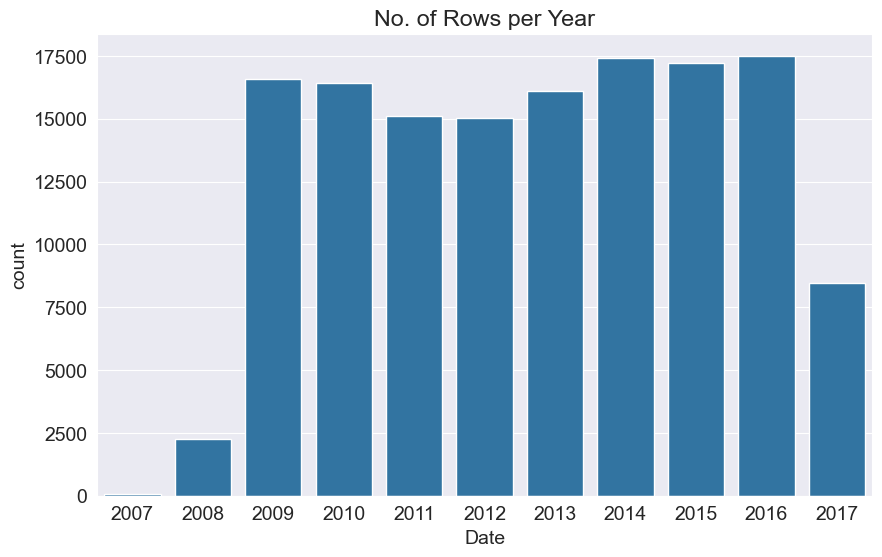

In [16]:
plt.title('No. of Rows per Year')
sns.countplot(x=pd.to_datetime(raw_df.Date).dt.year)

While working with chronological data, it's often a good idea to separate the training, validation and test sets with time, so that the model is trained on data from the past and evaluated on data from the future.

We'll use the data till 2014 for the training set, data from 2015 for the validation set, and the data from 2016 & 2017 for the test set.  

In [17]:
year= pd.to_datetime(raw_df.Date).dt.year
train_df = raw_df[year < 2015]
val_df = raw_df[year == 2015]
test_df = raw_df [year >2015]


In [18]:
print('train_df.shape :', train_df.shape)
print('val_df.shape :', val_df.shape)
print('test_df.shape :', test_df.shape)

train_df.shape : (98988, 23)
val_df.shape : (17231, 23)
test_df.shape : (25974, 23)


## Train-Validation-Test Split

Since weather observations are collected over time, a chronological split was used instead of a random split.

### Split Strategy

The dataset was divided based on year:

- Training Set: Years before 2015
- Validation Set: Year 2015
- Test Set: Years 2016 and later

### Dataset Sizes

| Dataset | Rows | Columns |
|----------|----------:|----------:|
| Training Set | 98,988 | 23 |
| Validation Set | 17,231 | 23 |
| Test Set | 25,974 | 23 |

### Why Use a Time-Based Split?

Weather forecasting is inherently a time-dependent problem. In practice, predictions are made on future observations using historical weather data.

A random train-test split could lead to information leakage because observations from similar weather periods may appear in both training and testing datasets.

By splitting chronologically:

- The model is trained on past weather observations.
- Hyperparameters are tuned using future unseen data from 2015.
- Final performance is evaluated on completely unseen observations from 2016 and 2017.

### Benefits

- Prevents data leakage
- Simulates real-world forecasting conditions
- Produces a more reliable estimate of model performance
- Ensures evaluation on future observations

### Conclusion

A chronological train-validation-test split was chosen because it better reflects the real-world objective of predicting future weather conditions from historical observations. This approach provides a more realistic and trustworthy evaluation of Decision Tree and Random Forest models.

### Input and Target Columns

Let's identify the input and target columns.

In [19]:
input_cols = list(train_df.columns)[1:-1]
target_col = 'RainTomorrow'

In [20]:
train_inputs = train_df[input_cols].copy()
train_targets = train_df[target_col].copy()

In [21]:
val_inputs = val_df[input_cols].copy()
val_targets = val_df[target_col].copy()

In [22]:
test_inputs = test_df[input_cols].copy()
test_targets = test_df[target_col].copy()

Let's also identify the numeric and categorical columns.


In [23]:
numeric_cols = train_inputs.select_dtypes(include=np.number).columns.tolist()
categorical_cols=train_inputs.select_dtypes('object').columns.tolist()

In [24]:
print(numeric_cols)

['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']


In [25]:
print(categorical_cols) 

['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']


### Imputing missing numeric values

In [26]:
train_inputs[numeric_cols].isna().sum().sort_values(ascending=False)

Sunshine         40696
Evaporation      37110
Cloud3pm         36766
Cloud9am         35764
Pressure9am       9345
Pressure3pm       9309
WindGustSpeed     6902
Humidity9am       1265
Humidity3pm       1186
WindSpeed3pm      1140
WindSpeed9am      1133
Rainfall          1000
Temp9am            783
Temp3pm            663
MinTemp            434
MaxTemp            198
dtype: int64

In [27]:
from sklearn.impute import SimpleImputer

In [28]:
imputer = SimpleImputer(strategy= 'mean').fit(raw_df[numeric_cols])

In [29]:
train_inputs[numeric_cols] = imputer.transform(train_inputs[numeric_cols])
val_inputs[numeric_cols] = imputer.transform(val_inputs[numeric_cols])
test_inputs[numeric_cols] = imputer.transform(test_inputs[numeric_cols])

In [30]:
train_inputs[numeric_cols].isna().sum()

MinTemp          0
MaxTemp          0
Rainfall         0
Evaporation      0
Sunshine         0
WindGustSpeed    0
WindSpeed9am     0
WindSpeed3pm     0
Humidity9am      0
Humidity3pm      0
Pressure9am      0
Pressure3pm      0
Cloud9am         0
Cloud3pm         0
Temp9am          0
Temp3pm          0
dtype: int64

### Scaling Numeric Features

In [31]:
raw_df[numeric_cols].describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,141556.000000,141871.000000,140787.000000,81350.000000,74377.000000,132923.000000,140845.000000,139563.000000,140419.000000,138583.000000,128179.000000,128212.000000,88536.000000,85099.000000,141289.000000,139467.000000
mean,12.186400,23.226784,2.349974,5.469824,7.624853,39.984292,14.001988,18.637576,68.843810,51.482606,1017.653758,1015.258204,4.437189,4.503167,16.987509,21.687235
std,6.403283,7.117618,8.465173,4.188537,3.781525,13.588801,8.893337,8.803345,19.051293,20.797772,7.105476,7.036677,2.887016,2.720633,6.492838,6.937594
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.500000,977.100000,0.000000,0.000000,-7.200000,-5.400000
25%,7.600000,17.900000,0.000000,2.600000,4.900000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.900000,1010.400000,1.000000,2.000000,12.300000,16.600000
50%,12.000000,22.600000,0.000000,4.800000,8.500000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.600000,1015.200000,5.000000,5.000000,16.700000,21.100000
75%,16.800000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.400000,1020.000000,7.000000,7.000000,21.600000,26.400000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.000000,1039.600000,9.000000,9.000000,40.200000,46.700000


In [32]:
from sklearn.preprocessing import MinMaxScaler

In [33]:
scaler = MinMaxScaler().fit(raw_df[numeric_cols])


## MinMaxScaler

`MinMaxScaler` is a feature scaling technique that transforms numerical values into a fixed range, typically between **0 and 1**.

### Formula

\[
X_{scaled} = \frac{X - X_{min}}{X_{max} - X_{min}}
\]

Where:

- \(X\) is the original value
- \(X_{min}\) is the minimum value in the feature
- \(X_{max}\) is the maximum value in the feature

### Example

Suppose the `MaxTemp` feature contains the following values:

| Original Value |
|---------------|
| 10 |
| 20 |
| 30 |
| 40 |

After applying MinMaxScaler:

| Original Value | Scaled Value |
|---------------|-------------|
| 10 | 0.00 |
| 20 | 0.33 |
| 30 | 0.67 |
| 40 | 1.00 |

The minimum value becomes 0 and the maximum value becomes 1, while all other values are scaled proportionally.

### Why Use MinMaxScaler?

Different features often have different ranges. For example:

| Feature | Range |
|----------|----------|
| Rainfall | 0 – 371 |
| Humidity | 0 – 100 |
| Pressure | 980 – 1041 |
| Temperature | -5 – 47 |

Without scaling, features with larger numerical ranges may dominate the learning process.

MinMaxScaler ensures that:

- All features are on a similar scale.
- Features become easier to compare.
- Model training becomes more stable.
- Optimization algorithms converge faster.

### When to Use MinMaxScaler?

MinMaxScaler is commonly used with:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Support Vector Machines (SVM)
- Neural Networks

### When is it Not Necessary?

Tree-based models such as:

- Decision Trees
- Random Forests
- XGBoost

do not require feature scaling because they use threshold-based splitting

In [34]:
train_inputs[numeric_cols] = scaler.transform(train_inputs[numeric_cols])
val_inputs[numeric_cols] = scaler.transform(val_inputs[numeric_cols])
test_inputs[numeric_cols] = scaler.transform(test_inputs[numeric_cols])

In [35]:
val_inputs.describe().loc[['min' , 'max']]

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
min,0.007075,0.030246,0.000000,0.000000,0.0,0.007752,0.000000,0.000000,0.04,0.0,0.125620,0.0816,0.000000,0.000000,0.021097,0.026871
max,0.952830,0.948960,0.666307,0.485517,1.0,1.000000,0.669231,0.850575,1.00,1.0,0.971901,0.9632,0.888889,0.888889,0.943038,0.925144


### Encoding Categorical Data

In [36]:
from sklearn.preprocessing import OneHotEncoder

In [37]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit(raw_df[categorical_cols])

In [38]:
encoded_cols = list(encoder.get_feature_names_out(categorical_cols))

The `get_feature_names_out()` method is used to retrieve the names of all columns generated by One-Hot Encoding. Since each category is converted into a separate binary feature, this method helps identify and label the newly created encoded columns correctly.

In [39]:
train_inputs[encoded_cols] = encoder.transform(train_inputs[categorical_cols])
val_inputs[encoded_cols] = encoder.transform(val_inputs[categorical_cols])
test_inputs[encoded_cols]= encoder.transform(test_inputs[categorical_cols])

C:\Users\Rohaan farooq\AppData\Local\Temp\ipykernel_11808\4011886082.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_inputs[encoded_cols] = encoder.transform(train_inputs[categorical_cols])
C:\Users\Rohaan farooq\AppData\Local\Temp\ipykernel_11808\4011886082.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_inputs[encoded_cols] = encoder.transform(train_inputs[categorical_cols])
C:\Users\Rohaan farooq\AppData\Local\Temp\ipykernel_11808\4011886082.py:1: PerformanceWarning: DataFrame is highly fragmented.  This i

In [40]:
train_inputs

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,Location_Adelaide,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,Location_Cobar,Location_CoffsHarbour,Location_Dartmoor,Location_Darwin,Location_GoldCoast,Location_Hobart,Location_Katherine,Location_Launceston,Location_Melbourne,Location_MelbourneAirport,Location_Mildura,Location_Moree,Location_MountGambier,Location_MountGinini,Location_Newcastle,Location_Nhil,Location_NorahHead,Location_NorfolkIsland,Location_Nuriootpa,Location_PearceRAAF,Location_Penrith,Location_Perth,Location_PerthAirport,Location_Portland,Location_Richmond,Location_Sale,Location_SalmonGums,Location_Sydney,Location_SydneyAirport,Location_Townsville,Location_Tuggeranong,Location_Uluru,Location_WaggaWagga,Location_Walpole,Location_Watsonia,Location_Williamtown,Location_Witchcliffe,Location_Wollongong,Location_Woomera,WindGustDir_E,WindGustDir_ENE,WindGustDir_ESE,WindGustDir_N,WindGustDir_NE,WindGustDir_NNE,WindGustDir_NNW,WindGustDir_NW,WindGustDir_S,WindGustDir_SE,WindGustDir_SSE,WindGustDir_SSW,WindGustDir_SW,WindGustDir_W,WindGustDir_WNW,WindGustDir_WSW,WindGustDir_nan,WindDir9am_E,WindDir9am_ENE,WindDir9am_ESE,WindDir9am_N,WindDir9am_NE,WindDir9am_NNE,WindDir9am_NNW,WindDir9am_NW,WindDir9am_S,WindDir9am_SE,WindDir9am_SSE,WindDir9am_SSW,WindDir9am_SW,WindDir9am_W,WindDir9am_WNW,WindDir9am_WSW,WindDir9am_nan,WindDir3pm_E,WindDir3pm_ENE,WindDir3pm_ESE,WindDir3pm_N,WindDir3pm_NE,WindDir3pm_NNE,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,WindDir3pm_nan,RainToday_No,RainToday_Yes,RainToday_nan
0,Albury,0.516509,0.523629,0.001617,0.037723,0.525852,W,0.294574,W,WNW,0.153846,0.275862,0.71,0.22,0.449587,0.4800,0.888889,0.500352,0.508439,0.522073,No,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,Albury,0.375000,0.565217,0.000000,0.037723,0.525852,WNW,0.294574,NNW,WSW,0.030769,0.252874,0.44,0.25,0.497521,0.4912,0.493021,0.500352,0.514768,0.570058,No,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,Albury,0.504717,0.576560,0.000000,0.037723,0.525852,WSW,0.310078,W,WSW,0.146154,0.298851,0.38,0.30,0.447934,0.5056,0.493021,0.222222,0.594937,0.548944,No,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3,Albury,0.417453,0.620038,0.000000,0.037723,0.525852,NE,0.139535,SE,E,0.084615,0.103448,0.45,0.16,0.613223,0.5712,0.493021,0.500352,0.533755,0.612284,No,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0

- As a final step, let's drop the textual categorical columns, so that we're left with just numeric data.

In [41]:
X_train = train_inputs[numeric_cols + encoded_cols]
X_val = val_inputs[numeric_cols + encoded_cols]
X_test = test_inputs[numeric_cols + encoded_cols]

In [42]:
X_test

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,Location_Adelaide,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,Location_Cobar,Location_CoffsHarbour,Location_Dartmoor,Location_Darwin,Location_GoldCoast,Location_Hobart,Location_Katherine,Location_Launceston,Location_Melbourne,Location_MelbourneAirport,Location_Mildura,Location_Moree,Location_MountGambier,Location_MountGinini,Location_Newcastle,Location_Nhil,Location_NorahHead,Location_NorfolkIsland,Location_Nuriootpa,Location_PearceRAAF,Location_Penrith,Location_Perth,Location_PerthAirport,Location_Portland,Location_Richmond,Location_Sale,Location_SalmonGums,Location_Sydney,Location_SydneyAirport,Location_Townsville,Location_Tuggeranong,Location_Uluru,Location_WaggaWagga,Location_Walpole,Location_Watsonia,Location_Williamtown,Location_Witchcliffe,Location_Wollongong,Location_Woomera,WindGustDir_E,WindGustDir_ENE,WindGustDir_ESE,WindGustDir_N,WindGustDir_NE,WindGustDir_NNE,WindGustDir_NNW,WindGustDir_NW,WindGustDir_S,WindGustDir_SE,WindGustDir_SSE,WindGustDir_SSW,WindGustDir_SW,WindGustDir_W,WindGustDir_WNW,WindGustDir_WSW,WindGustDir_nan,WindDir9am_E,WindDir9am_ENE,WindDir9am_ESE,WindDir9am_N,WindDir9am_NE,WindDir9am_NNE,WindDir9am_NNW,WindDir9am_NW,WindDir9am_S,WindDir9am_SE,WindDir9am_SSE,WindDir9am_SSW,WindDir9am_SW,WindDir9am_W,WindDir9am_WNW,WindDir9am_WSW,WindDir9am_nan,WindDir3pm_E,WindDir3pm_ENE,WindDir3pm_ESE,WindDir3pm_N,WindDir3pm_NE,WindDir3pm_NNE,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,WindDir3pm_nan,RainToday_No,RainToday_Yes,RainToday_nan
2498,0.681604,0.801512,0.000000,0.037723,0.525852,0.372093,0.000000,0.080460,0.46,0.17,0.543802,0.5136,0.777778,0.333333,0.702532,0.808061,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2499,0.693396,0.725898,0.001078,0.037723,0.525852,0.341085,0.069231,0.195402,0.54,0.30,0.505785,0.5008,0.888889,0.888889,0.675105,0.712092,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2500,0.634434,0.527410,0.005930,0.037723,0.525852,0.325581,0.084615,0.448276,0.62,0.67,0.553719,0.6032,0.888889,0.888889,0.611814,0.477927,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2501,0.608491,0.538752,0.042049,0.037723,0.525852,0.255814,0.069231,0.195402,0.74,0.65,0.618182,0.6304,0.888889,0.888889,0.556962,0.518234,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.

----- 
## Training and Visualizing Decision Trees

A decision tree is a supervised machine learning algorithm used for both classification and regression tasks. It works by repeatedly splitting the dataset into smaller subsets based on the values of input features.

In a real-world scenario, a decision tree resembles a sequence of hierarchical decisions where each decision leads to a different outcome.

<img src="https://i.imgur.com/qSH4lqz.png" width="480">

Similarly, in machine learning, a Decision Tree learns a set of decision rules from the training data. Instead of manually defining these rules, the algorithm automatically identifies the most informative features and split points.

### How Decision Trees Work

1. The algorithm starts with the entire dataset at the root node.
2. It searches for the feature that best separates the target classes.
3. The dataset is split into smaller groups based on the selected feature.
4. This process is repeated recursively for each child node.
5. Splitting continues until a stopping criterion is reached, such as:
   - Maximum tree depth
   - Minimum samples per leaf
   - Pure leaf nodes

### Example

A Decision Tree for rainfall prediction might learn rules such as:

- If Humidity3pm > 70, then RainTomorrow = Yes
- Else if Pressure3pm < 1012, then RainTomorrow = Yes
- Otherwise RainTomorrow = No

### Advantages of Decision Trees

- Easy to understand and interpret
- Can handle both numerical and categorical variables
- Requires little data preprocessing
- Captures non-linear relationships
- Produces human-readable decision rules

### Limitations

- Prone to overfitting when trees become very deep
- Small changes in data can produce different tree structures
- Individual decision trees may not generalize well

### Why Use Decision Trees?

Decision Trees are particularly useful because they provide interpretable predictions and automatically identify the most important features influencing the target variable. They also form the foundation of advanced ensemble methods such as Random Forests and Gradient Boosting.

### Training

We can use `DecisionTreeClassifier` from `sklearn.tree` to train a decision tree.

In [43]:
from sklearn.tree import DecisionTreeClassifier


### DecisionTreeClassifier

A Decision Tree Classifier is used for classification problems where the target variable belongs to one of several categories.

For example:

- RainTomorrow = Yes / No
- Spam = Yes / No
- Disease = Positive / Negative

The model learns a series of decision rules from the training data and assigns each observation to a class.

### DecisionTreeRegressor

A Decision Tree Regressor is used for regression problems where the target variable is numerical.

Examples include:

- House Prices
- Medical Expenses


In [44]:
model=DecisionTreeClassifier(random_state=42)
#object of the class

> `random_state=42` ensures reproducibility by making the random operations inside the algorithm produce the same results every time the model is trained.

In [45]:
%%time
model.fit(X_train , train_targets)

CPU times: total: 5.81 s
Wall time: 6.38 s


DecisionTreeClassifier(random_state=42)

An optimal decision tree has now been created using the training data.

### Evaluation

Let's evaluate the decision tree using the accuracy score.

In [46]:
train_preds = model.predict(X_train)

In [47]:
train_preds

array(['No', 'No', 'No', ..., 'No', 'No', 'No'], dtype=object)

In [48]:
pd.value_counts(train_preds)

C:\Users\Rohaan farooq\AppData\Local\Temp\ipykernel_11808\1258350197.py:1: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  pd.value_counts(train_preds)


No     76707
Yes    22281
Name: count, dtype: int64

In [49]:
from sklearn.metrics import accuracy_score , confusion_matrix

Seems like the decision tree is quite confident about its predictions.

Let's check the accuracy of its predictions.

In [50]:
accuracy_score(train_targets , train_preds)

0.9999797955307714

The training set accuracy is close to 100%! But we can't rely solely on the training set accuracy, we must evaluate the model on the validation set too. 

We can make predictions and compute accuracy in one step using `model.score`

In [51]:
model.score(X_val , val_targets)

0.7921188555510418

Although the training accuracy is 100%, the accuracy on the validation set is just about 79%, which is only marginally better then always predicting "No". 

In [52]:
val_targets.value_counts() / len(val_targets)

RainTomorrow
No     0.788289
Yes    0.211711
Name: count, dtype: float64

It appears that the model has learned the training examples perfect, and doesn't generalize well to previously unseen examples. This phenomenon is called "overfitting", and reducing overfitting is one of the most important parts of any machine learning project.

### Visualization

We can visualize the decision tree _learned_ from the training data.

In [53]:
from sklearn.tree import plot_tree , export_text

[Text(0.5, 0.875, 'Humidity3pm <= 0.715\ngini = 0.349\nsamples = 98988\nvalue = [76705, 22283]'),
 Text(0.25, 0.625, 'Rainfall <= 0.004\ngini = 0.248\nsamples = 82418\nvalue = [70439.0, 11979.0]'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'Sunshine <= 0.525\ngini = 0.198\nsamples = 69252\nvalue = [61538.0, 7714.0]'),
 Text(0.0625, 0.125, '\n  (...)  \n'),
 Text(0.1875, 0.125, '\n  (...)  \n'),
 Text(0.375, 0.375, 'Humidity3pm <= 0.512\ngini = 0.438\nsamples = 13166\nvalue = [8901, 4265]'),
 Text(0.3125, 0.125, '\n  (...)  \n'),
 Text(0.4375, 0.125, '\n  (...)  \n'),
 Text(0.75, 0.625, 'Humidity3pm <= 0.825\ngini = 0.47\nsamples = 16570\nvalue = [6266, 10304]'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'WindGustSpeed <= 0.279\ngini = 0.499\nsamples = 9136\nvalue = [4804, 4332]'),
 Text(0.5625, 0.125, '\n  (...)  \n'),
 Text(0.6875, 0.125, '\n  (...)  \n'),
 Text(0.875, 0.375, 'Rainfall <= 0.01\ngini = 0.316\nsamples = 7434\nvalue = [1462, 5972]'),
 Text(0.8125, 0.125,

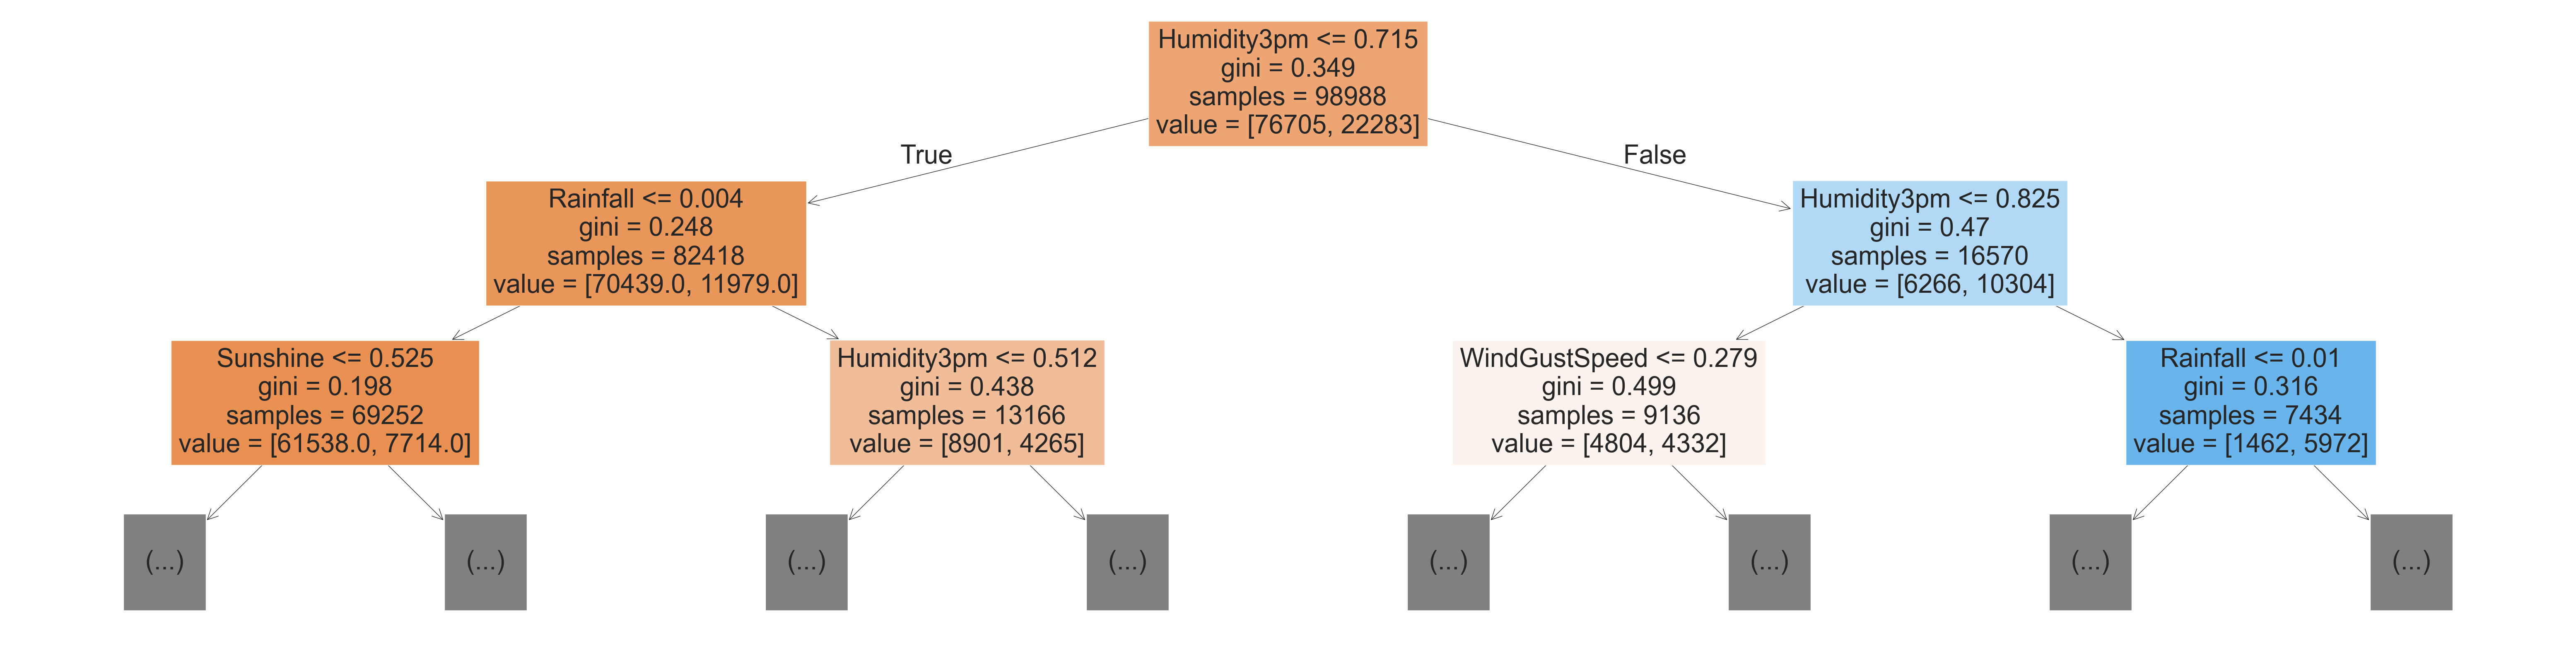

In [54]:
plt.figure(figsize=(80,20))
plot_tree(model,feature_names=X_train.columns , max_depth =2, filled=True)

Can you see how the model classifies a given input as a series of decisions? The tree is truncated here, but following any path from the root node down to a leaf will result in "Yes" or "No". Do you see how a decision tree differs from a logistic regression model?


**How a Decision Tree is Created**

Note the `gini` value in each box. This is the loss function used by the decision tree to decide which column should be used for splitting the data, and at what point the column should be split. A lower Gini index indicates a better split. A perfect split (only one class on each side) has a Gini index of 0. 

For a mathematical discussion of the Gini Index, watch this video: https://www.youtube.com/watch?v=-W0DnxQK1Eo . It has the following formula:

<img src="https://i.imgur.com/CSC0gAo.png" width="240">

Conceptually speaking, while training the models evaluates all possible splits across all possible columns and picks the best one. Then, it recursively performs an optimal split for the two portions. In practice, however, it's very inefficient to check all possible splits, so the model uses a heuristic (predefined strategy) combined with some randomization.

The iterative approach of the machine learning workflow in the case of a decision tree involves growing the tree layer-by-layer:

<img src="https://www.deepnetts.com/blog/wp-content/uploads/2019/02/SupervisedLearning.png" width="480">


Let's check the depth of the tree that was created.

In [55]:
model.tree_.max_depth

48

We can also display the tree as text, which can be easier to follow for deeper trees.

In [56]:
tree_text = export_text(model , max_depth=10 , feature_names=list(X_train.columns))
print(tree_text[:5000])

|--- Humidity3pm <= 0.72
|   |--- Rainfall <= 0.00
|   |   |--- Sunshine <= 0.52
|   |   |   |--- Pressure3pm <= 0.58
|   |   |   |   |--- WindGustSpeed <= 0.36
|   |   |   |   |   |--- Humidity3pm <= 0.28
|   |   |   |   |   |   |--- WindDir9am_NE <= 0.50
|   |   |   |   |   |   |   |--- Location_Watsonia <= 0.50
|   |   |   |   |   |   |   |   |--- Cloud9am <= 0.83
|   |   |   |   |   |   |   |   |   |--- WindSpeed3pm <= 0.07
|   |   |   |   |   |   |   |   |   |   |--- Pressure3pm <= 0.46
|   |   |   |   |   |   |   |   |   |   |   |--- class: Yes
|   |   |   |   |   |   |   |   |   |   |--- Pressure3pm >  0.46
|   |   |   |   |   |   |   |   |   |   |   |--- class: No
|   |   |   |   |   |   |   |   |   |--- WindSpeed3pm >  0.07
|   |   |   |   |   |   |   |   |   |   |--- MinTemp <= 0.32
|   |   |   |   |   |   |   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |   |   |   |   |   |   |--- MinTemp >  0.32
|   |   |   |   |   |   |   |   |   |   |   |--- truncated

### Why is the Training Accuracy 100% while the Validation Accuracy is Lower?

A training accuracy of **100%** means that the model has perfectly memorized all the training examples. However, the validation accuracy is measured on data that the model has never seen before.

This difference usually occurs due to **overfitting**. The decision tree has learned not only the underlying patterns in the training data but also the noise and specific details unique to the training set. As a result, it performs perfectly on the training data but struggles to generalize to new, unseen data.

In other words:

- **Training Accuracy = 100%** → The model memorized the training dataset.
- **Lower Validation Accuracy** → The model cannot generalize equally well to unseen data.
- **Reason** → The decision tree is too complex and has overfit the training data.

To reduce overfitting, we can limit the complexity of the tree using parameters such as:
- `max_depth`
- `min_samples_split`
- `min_samples_leaf`
- `max_leaf_nodes`

A good model should have high training accuracy and validation accuracy that are reasonably close to each other.

--- 
### Feature Importance

Based on the gini index computations, a decision tree assigns an "importance" value to each feature. These values can be used to interpret the results given by a decision tree.

In [57]:
model.feature_importances_

array([3.48942086e-02, 3.23605486e-02, 5.91385668e-02, 2.49619907e-02,
       4.94652143e-02, 5.63334673e-02, 2.80205998e-02, 2.98128801e-02,
       4.02182908e-02, 2.61441297e-01, 3.44145027e-02, 6.20573699e-02,
       1.36406176e-02, 1.69229866e-02, 3.50001550e-02, 3.04064076e-02,
       2.24086587e-03, 2.08018104e-03, 1.27475954e-03, 7.26936324e-04,
       1.39779517e-03, 1.15264873e-03, 6.92808159e-04, 1.80675598e-03,
       1.08370901e-03, 1.19773895e-03, 8.87119103e-04, 2.15764220e-03,
       1.67094731e-03, 7.98919493e-05, 1.10558668e-03, 1.42008656e-03,
       4.10087635e-04, 1.09028115e-03, 1.44164766e-03, 9.08284767e-04,
       1.05770304e-03, 6.18133455e-04, 1.80387272e-03, 2.10403527e-03,
       2.74413333e-04, 7.31599405e-04, 1.35408990e-03, 1.54759332e-03,
       1.30917564e-03, 1.07134670e-03, 8.36408023e-04, 1.62662229e-03,
       1.00326116e-03, 2.16053455e-03, 8.46802258e-04, 1.88919081e-03,
       9.29325203e-04, 1.29545157e-03, 1.27604831e-03, 5.12736888e-04,
      

Let's turn this into a dataframe and visualize the most important features.

In [58]:
importance_df = pd.DataFrame({
    'feature' : X_train.columns , 
    'importance' : model.feature_importances_
}).sort_values('importance' , ascending=False)

In [59]:
importance_df.head(10)

,feature,importance
9,Humidity3pm,0.261441
11,Pressure3pm,0.062057
2,Rainfall,0.059139
5,WindGustSpeed,0.056333
4,Sunshine,0.049465
8,Humidity9am,0.040218
14,Temp9am,0.035000
0,MinTemp,0.034894
10,Pressure9am,0.034415
1,MaxTemp,0.032361


<AxesSubplot:title={'center':'Feature Importance'}, xlabel='importance', ylabel='feature'>

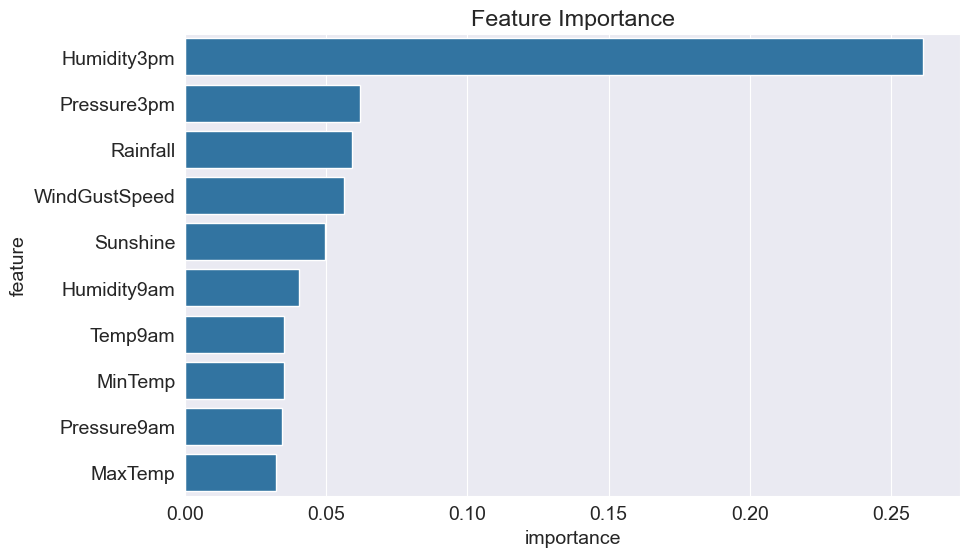

In [60]:
plt.title('Feature Importance')
sns.barplot(data=importance_df.head(10) , x='importance' , y='feature')

## Hyperparameter Tuning and Overfitting

As we saw in the previous section, our decision tree classifier memorized all training examples, leading to a 100% training accuracy, while the validation accuracy was only marginally better than a dumb baseline model. This phenomenon is called overfitting, and in this section, we'll look at some strategies for reducing overfitting.

The `DecisionTreeClassifier` accepts several arguments, some of which can be modified to reduce overfitting.

These arguments are called hyperparameters because they must be configured manually (as opposed to the parameters within the model which are _learned_ from the data. We'll explore a couple of hyperparameters:

- `max_depth`
- `max_leaf_nodes`

### `max_depth`

By reducing the maximum depth of the decision tree, we can prevent the tree from memorizing all training examples, which may lead to better generalization

### Hyperparameters

Hyperparameters are settings that are specified before training a machine learning model. Unlike model parameters, hyperparameters are not learned from the data and must be chosen by the user.

Examples of hyperparameters include:

- `max_depth`
- `min_samples_split`
- `n_estimators`
- `C`
- `learning_rate`

Hyperparameters control how the model learns and can have a significant impact on model performance. Finding the best combination of hyperparameters is known as **hyperparameter tuning**.

In [61]:
model = DecisionTreeClassifier(max_depth=3 , random_state=42)

In [62]:
model.fit(X_train , train_targets)

DecisionTreeClassifier(max_depth=3, random_state=42)

We can compute the accuracy of the model on the training and validation sets using `model.score`

In [63]:
model.score(X_train , train_targets)

0.8291308037337859

In [64]:
model.score(X_val , val_targets)

0.8334397307178921

Great, while the training accuracy of the model has gone down, the validation accuracy of the model has increased significantly.

In [65]:
model.classes_

array(['No', 'Yes'], dtype=object)

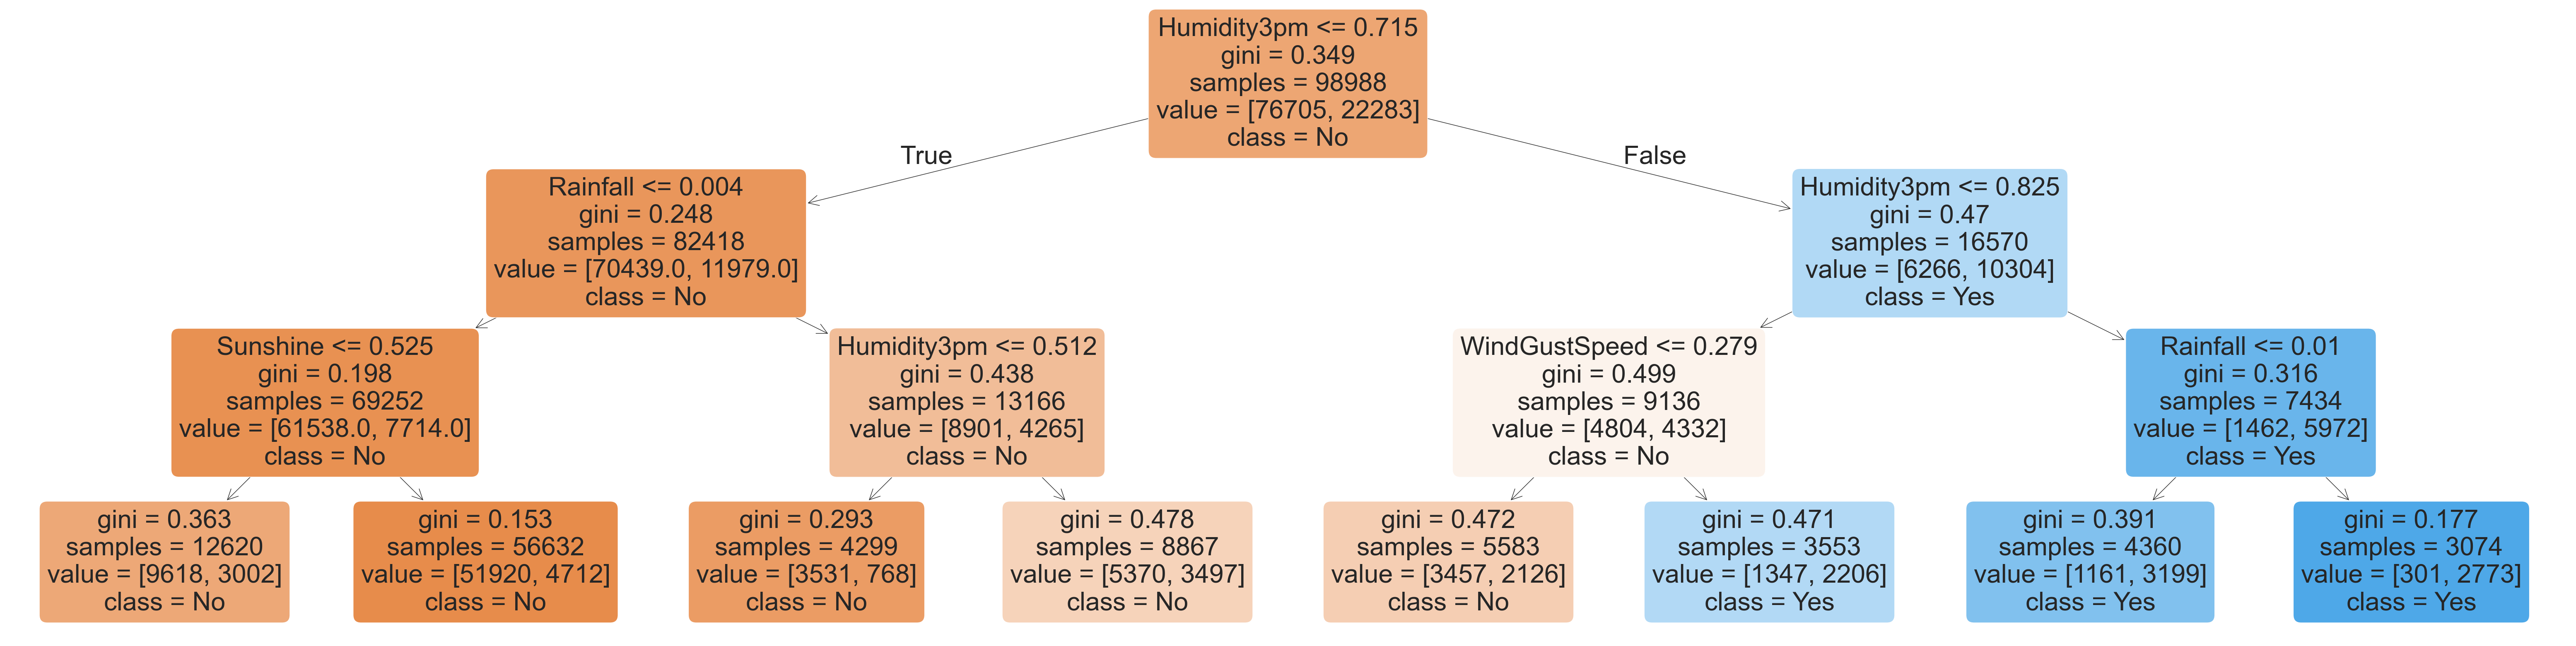

In [66]:
plt.figure(figsize=(80,20))
plot_tree(model, feature_names=X_train.columns, filled=True, rounded=True, class_names=model.classes_);

> **EXERCISE:** Study the decision tree diagram carefully and understand what each of the terms `gini`, `samples`, `value`, and `class` mean.

## Understanding Decision Tree Terminology

Each node in a Decision Tree contains useful information that helps explain how the model makes decisions.

### 1. Gini

The **Gini Impurity** measures how mixed the classes are within a node.

- A Gini value of **0** indicates a perfectly pure node where all observations belong to the same class.
- Higher Gini values indicate a greater mixture of classes.
- The Decision Tree attempts to reduce the Gini Impurity at each split.

Example:

```text
gini = 0.198

In [67]:
print(export_text(model , feature_names=list(X_train.columns)))

|--- Humidity3pm <= 0.72
|   |--- Rainfall <= 0.00
|   |   |--- Sunshine <= 0.52
|   |   |   |--- class: No
|   |   |--- Sunshine >  0.52
|   |   |   |--- class: No
|   |--- Rainfall >  0.00
|   |   |--- Humidity3pm <= 0.51
|   |   |   |--- class: No
|   |   |--- Humidity3pm >  0.51
|   |   |   |--- class: No
|--- Humidity3pm >  0.72
|   |--- Humidity3pm <= 0.82
|   |   |--- WindGustSpeed <= 0.28
|   |   |   |--- class: No
|   |   |--- WindGustSpeed >  0.28
|   |   |   |--- class: Yes
|   |--- Humidity3pm >  0.82
|   |   |--- Rainfall <= 0.01
|   |   |   |--- class: Yes
|   |   |--- Rainfall >  0.01
|   |   |   |--- class: Yes



Let's experiment with different depths using a helper function.

In [68]:
def max_depth_error(md):
    model = DecisionTreeClassifier(max_depth=md , random_state=42)
    model.fit(X_train , train_targets)
    train_acc = 1-model.score(X_train , train_targets)
    val_acc = 1-model.score(X_val , val_targets)
    return{'Max Depth' : md , 'Training Error' : train_acc , 'validation Error' : val_acc}

In [69]:
%%time

error_df = pd.DataFrame([max_depth_error(md) for md in range(1,21)])

error_df

CPU times: total: 52.4 s
Wall time: 57.8 s


,Max Depth,Training Error,validation Error
0,1,0.184315,0.177935
1,2,0.179547,0.172712
2,3,0.170869,0.166560
3,4,0.165707,0.164355
4,5,0.160676,0.159074
5,6,0.156271,0.157275
6,7,0.153312,0.154605
7,8,0.147806,0.158029
8,9,0.140906,0.156578
9,10,0.132945,0.157333


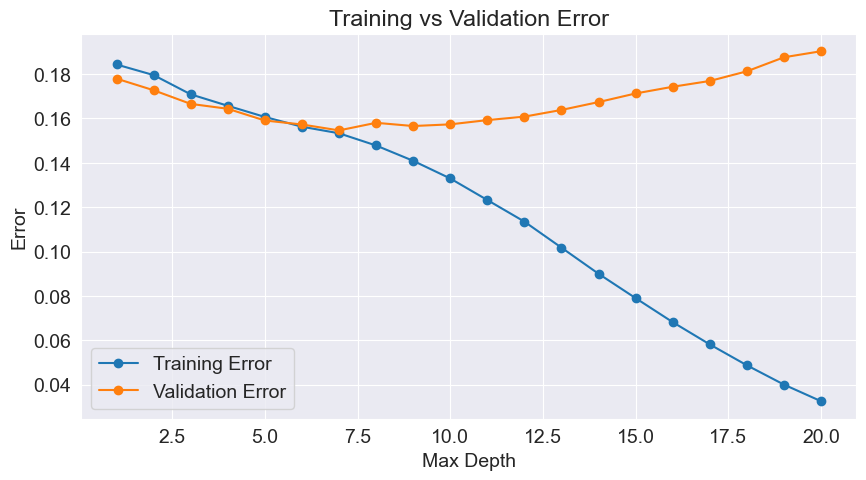

In [70]:
plt.figure(figsize=(10,5))

plt.plot(
    error_df['Max Depth'].to_numpy(),
    error_df['Training Error'].to_numpy(),
    marker='o',
    label='Training Error'
)

plt.plot(
    error_df['Max Depth'].to_numpy(),
    error_df['validation Error'].to_numpy(),
    marker='o',
    label='Validation Error'
)

plt.xlabel('Max Depth')
plt.ylabel('Error')
plt.title('Training vs Validation Error')
plt.legend()

plt.show()

## Effect of Maximum Tree Depth

To determine the optimal complexity of the Decision Tree, models were trained with different values of `max_depth`.

### Observations

- As tree depth increases, the training error decreases continuously.
- A deeper tree is able to learn more complex patterns from the training data.
- Validation error initially decreases, indicating improved learning and better generalization.
- The validation error reaches its minimum at approximately `max_depth = 7`.
- Beyond this point, validation error starts increasing while training error continues to decrease.

### Evidence of Overfitting

The divergence between training and validation error after depth 7 indicates that the model begins memorizing the training data rather than learning general patterns.

Characteristics of overfitting:

- Very low training error
- Increasing validation error
- Reduced performance on unseen data

### Optimal Depth

The lowest validation error was achieved at:

```text
max_depth = 7


This is a common pattern you'll see with all machine learning algorithms:

<img src="https://i.imgur.com/EJCrSZw.png" width="480">


You'll often need to tune hyperparameters carefully to find the optimal fit. In the above case, it appears that a maximum depth of 7 results in the lowest validation error.

In [71]:
model = DecisionTreeClassifier(max_depth=7 , random_state = 42)
model.fit(X_train , train_targets)
model.score(X_val , val_targets)


0.8453949277465034

### `max_leaf_nodes`

Another way to control the size of complexity of a decision tree is to limit the number of leaf nodes. This allows branches of the tree to have varying depths. 

In [72]:
model = DecisionTreeClassifier(max_leaf_nodes = 128 , random_state=42)

In [73]:
model.fit(X_train , train_targets)

DecisionTreeClassifier(max_leaf_nodes=128, random_state=42)

In [74]:
model.score(X_train , train_targets)

0.8480421869317493

In [75]:
model.score(X_val , val_targets)

0.8442342290058615

In [76]:
model.tree_.max_depth

12

Notice that the model was able to achieve a greater depth of 12 for certain paths while keeping other paths shorter.

### Understanding `max_leaf_nodes`

The `max_leaf_nodes` parameter limits the total number of leaf nodes that can be created in a Decision Tree.

Unlike `max_depth`, it does not directly control the height of the tree.

For example:

```python
DecisionTreeClassifier(max_leaf_nodes=128)

> `max_depth` limits how deep the tree can grow, whereas `max_leaf_nodes` limits how many final leaf nodes the tree can have, allowing branches to grow to different depths.

Notice that the model was able to achieve a greater depth of 12 for certain paths while keeping other paths shorter.

In [77]:
model_text = export_text(model , feature_names=list(X_train.columns))
print(model_text[:3000])

|--- Humidity3pm <= 0.72
|   |--- Rainfall <= 0.00
|   |   |--- Sunshine <= 0.52
|   |   |   |--- Pressure3pm <= 0.58
|   |   |   |   |--- WindGustSpeed <= 0.36
|   |   |   |   |   |--- Humidity3pm <= 0.28
|   |   |   |   |   |   |--- class: No
|   |   |   |   |   |--- Humidity3pm >  0.28
|   |   |   |   |   |   |--- Sunshine <= 0.05
|   |   |   |   |   |   |   |--- class: Yes
|   |   |   |   |   |   |--- Sunshine >  0.05
|   |   |   |   |   |   |   |--- Pressure3pm <= 0.43
|   |   |   |   |   |   |   |   |--- class: Yes
|   |   |   |   |   |   |   |--- Pressure3pm >  0.43
|   |   |   |   |   |   |   |   |--- Humidity3pm <= 0.57
|   |   |   |   |   |   |   |   |   |--- WindDir9am_NE <= 0.50
|   |   |   |   |   |   |   |   |   |   |--- WindDir9am_NNE <= 0.50
|   |   |   |   |   |   |   |   |   |   |   |--- class: No
|   |   |   |   |   |   |   |   |   |   |--- WindDir9am_NNE >  0.50
|   |   |   |   |   |   |   |   |   |   |   |--- class: No
|   |   |   |   |   |   |   |   |   |--- WindD

> **EXERCISE:** Find the combination of `max_depth` and `max_leaf_nodes` that results in the highest validation accuracy.

To optimize the Decision Tree model, different combinations of `max_depth` and `max_leaf_nodes` will be tested and evaluated using the validation dataset.

In [78]:
results = [] 

In [79]:
for md in range (3 , 11):
    for mln in [16 , 32 , 64 , 128 , 256]:
        model = DecisionTreeClassifier(max_depth = md , max_leaf_nodes = mln , random_state = 42)
        model.fit(X_train , train_targets)
        results.append({'max_depth' : md , 'max_leaf_nodes' : mln , 'validation_accuracy' : model.score(X_val , val_targets)})

In [80]:
results_df = pd.DataFrame(results)

results_df.sort_values('validation_accuracy' , ascending = False).head(10)

,max_depth,max_leaf_nodes,validation_accuracy
39,10,256,0.845859
24,7,256,0.845395
23,7,128,0.845395
34,9,256,0.845105
38,10,128,0.844640
33,9,128,0.844640
28,8,128,0.843828
22,7,64,0.843480
27,8,64,0.843248
37,10,64,0.843248


In [81]:
best_row = results_df.loc[
    results_df['validation_accuracy'].idxmax()
]
best_row

max_depth               10.000000
max_leaf_nodes         256.000000
validation_accuracy      0.845859
Name: 39, dtype: float64

> **EXERCISE:** Find the combination of `max_depth` and `max_leaf_nodes` that results in the highest validation accuracy.

### Hyperparameter Tuning

To identify the optimal Decision Tree configuration, different combinations of `max_depth` and `max_leaf_nodes` were tested and evaluated using the validation dataset.

### Best Hyperparameter Combination

| Hyperparameter | Value |
|---------------|--------|
| max_depth | 10 |
| max_leaf_nodes | 256 |
| Validation Accuracy | 84.59% |

### Observations

- Increasing the maximum depth allowed the model to learn more complex decision rules.
- Increasing the number of leaf nodes provided additional flexibility for splitting the data.
- Very small trees underfit the data and resulted in lower validation accuracy.
- The best performance was achieved using a moderately complex tree with sufficient depth and leaf nodes.

### Conclusion

The highest validation accuracy of **84.59%** was achieved using:

> **EXERCISE:** Explore and experiment with other arguments of `DecisionTreeClassifier`.

Apart from `max_depth` and `max_leaf_nodes`, several other hyperparameters can influence the performance of a Decision Tree model. In this experiment, different values of `criterion`, `min_samples_split`, and `min_samples_leaf` were tested and their validation accuracies were compared.

In [82]:
for criterion in['gini' , 'entropy' , 'log_loss']:
    model=DecisionTreeClassifier(criterion=criterion , max_depth= 10 ,
                                 max_leaf_nodes=256 , random_state=42)
    model.fit(X_train , train_targets)
    print(criterion , model.score(X_val , val_targets))


gini 0.8458592072427601
entropy 0.843305670013348
log_loss 0.843305670013348


### Exploring Different Split Criteria

The `criterion` parameter controls how the Decision Tree measures the quality of a split.

The following criteria were tested:

| Criterion | Validation Accuracy |
|------------|-------------------|
| gini | 84.59% |
| entropy | 84.33% |
| log_loss | 84.33% |

### Observations

- The `gini` criterion achieved the highest validation accuracy.
- Both `entropy` and `log_loss` produced identical validation accuracies.
- The performance differences are relatively small, indicating that the model is not highly sensitive to the choice of splitting criterion.

### Conclusion

The `gini` criterion performed slightly better than the other tested criteria and was selected as the preferred splitting criterion for this dataset.

### Criterion

The `criterion` parameter determines how the quality of a split is measured.

- `gini`: Uses Gini Impurity.
- `entropy`: Uses Information Gain.
- `log_loss`: Uses Logistic Loss.

The validation accuracies were compared to determine which splitting criterion performed best.

In [83]:
for mss in [2 , 5 , 10 , 20 , 50]:
    model = DecisionTreeClassifier(max_depth= 10 , max_leaf_nodes=256 ,min_samples_split=mss,random_state=42 )
    model.fit(X_train , train_targets)

    print(mss, model.score(X_val , val_targets))

2 0.8458592072427601
5 0.8458592072427601
10 0.8458592072427601
20 0.845801172305728
50 0.845743137368696


### min_samples_split

The `min_samples_split` parameter specifies the minimum number of samples required before a node can be split.

Larger values create simpler trees and may help reduce overfitting.

In [84]:
for msl in [1 , 2 , 5 , 10 , 20]:
    model=DecisionTreeClassifier(max_depth=10 , max_leaf_nodes=256 , min_samples_leaf = msl , random_state=42)
    model.fit(X_train ,  train_targets)
    print(msl, model.score(X_val , val_targets))

1 0.8458592072427601
2 0.8458592072427601
5 0.8458592072427601
10 0.845801172305728
20 0.8459172421797923


## Training a Random Forest

While tuning the hyperparameters of a single decision tree may lead to some improvements, a much more effective strategy is to combine the results of several decision trees trained with slightly different parameters. This is called a random forest. 

The key idea here is that each decision tree in the forest will make different kinds of errors, and upon averaging, many of their errors will cancel out. This idea is also known as the "wisdom of the crowd" in common parlance:

<img src="https://i.imgur.com/4Dg0XK4.png" width="480">

A random forest works by averaging/combining the results of several decision trees:

<img src="https://1.bp.blogspot.com/-Ax59WK4DE8w/YK6o9bt_9jI/AAAAAAAAEQA/9KbBf9cdL6kOFkJnU39aUn4m8ydThPenwCLcBGAsYHQ/s0/Random%2BForest%2B03.gif" width="640">


We'll use the `RandomForestClassifier` class from `sklearn.ensemble`.

In [85]:
from sklearn.ensemble import RandomForestClassifier

In [86]:
model = RandomForestClassifier(n_jobs=-1 , random_state=40)

In [87]:
model.fit(X_train , train_targets)

RandomForestClassifier(n_jobs=-1, random_state=40)

In [88]:
model.score(X_train , train_targets)

0.9999696932961571

In [89]:
model.score(X_val , val_targets)

0.8553189019789914

Once again, the training accuracy is 100%, but this time the validation accuracy is much better. In fact, it is better than the best single decision tree we had trained so far. Do you see the power of random forests?

This general technique of combining the results of many models is called "ensembling", it works because most errors of individual models cancel out on averaging. Here's what it looks like visually:

<img src="https://i.imgur.com/qJo8D8b.png" width="480">


We can also look at the probabilities for the predictions. The probability of a class is simply the fraction of trees which that predicted the given class.

In [90]:
train_proba = model.predict_proba(X_train)
train_proba

array([[0.96, 0.04],
       [0.98, 0.02],
       [0.99, 0.01],
       ...,
       [0.98, 0.02],
       [0.99, 0.01],
       [1.  , 0.  ]])

We can can access individual decision trees using `model.estimators_`

In [91]:
model.estimators_[0]

DecisionTreeClassifier(max_features='sqrt', random_state=1751002438)

[Text(0.5, 0.875, 'Humidity9am <= 0.755\ngini = 0.35\nsamples = 62507\nvalue = [76590, 22398]\nclass = No'),
 Text(0.25, 0.625, 'WindSpeed9am <= 0.192\ngini = 0.254\nsamples = 39131\nvalue = [52622, 9255]\nclass = No'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'Cloud9am <= 0.611\ngini = 0.238\nsamples = 33801\nvalue = [46093.0, 7391.0]\nclass = No'),
 Text(0.0625, 0.125, '\n  (...)  \n'),
 Text(0.1875, 0.125, '\n  (...)  \n'),
 Text(0.375, 0.375, 'RainToday_nan <= 0.5\ngini = 0.346\nsamples = 5330\nvalue = [6529.0, 1864.0]\nclass = No'),
 Text(0.3125, 0.125, '\n  (...)  \n'),
 Text(0.4375, 0.125, '\n  (...)  \n'),
 Text(0.75, 0.625, 'WindGustSpeed <= 0.302\ngini = 0.457\nsamples = 23376\nvalue = [23968, 13143]\nclass = No'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'Pressure3pm <= 0.586\ngini = 0.405\nsamples = 17858\nvalue = [20360, 7979]\nclass = No'),
 Text(0.5625, 0.125, '\n  (...)  \n'),
 Text(0.6875, 0.125, '\n  (...)  \n'),
 Text(0.875, 0.375, 'MaxTemp <= 0.47

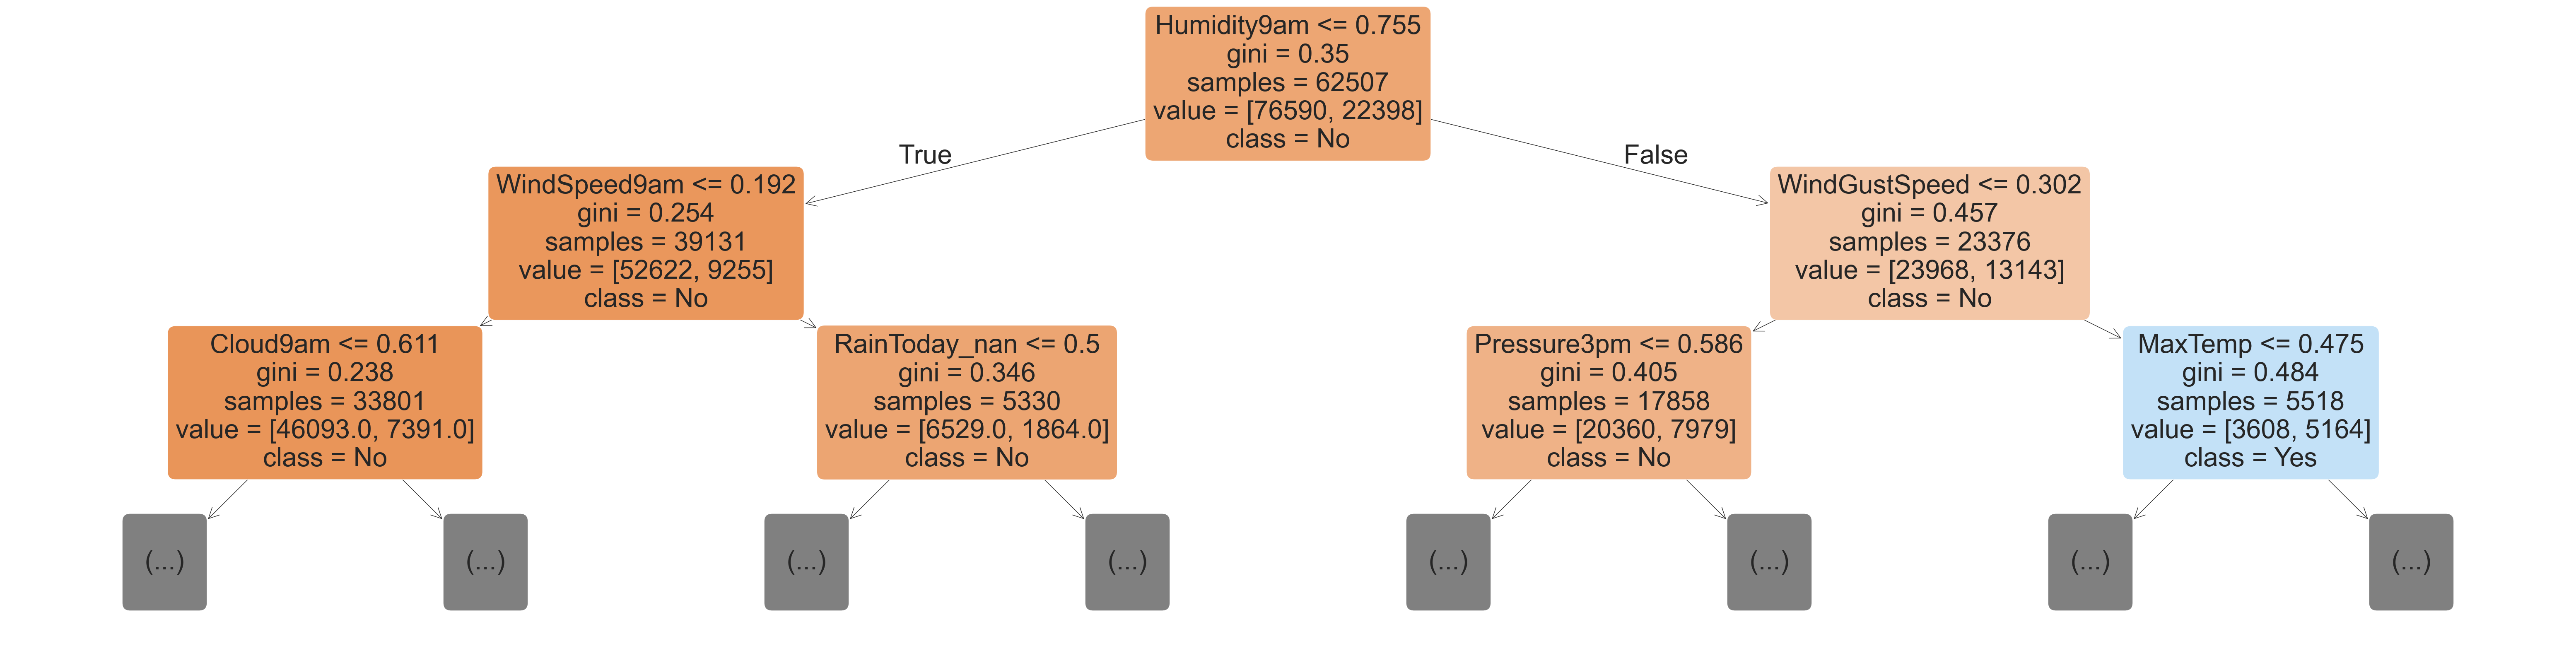

In [92]:
plt.figure(figsize=(80 , 20))
plot_tree(model.estimators_[0] ,max_depth=2 , feature_names=X_train.columns , filled=True ,rounded=True, class_names=model.classes_)

[Text(0.5, 0.875, 'Rainfall <= 0.001\ngini = 0.349\nsamples = 62519\nvalue = [76702, 22286]\nclass = No'),
 Text(0.25, 0.625, 'WindDir3pm_NNW <= 0.5\ngini = 0.241\nsamples = 45092\nvalue = [61423, 10026]\nclass = No'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'Evaporation <= 0.029\ngini = 0.235\nsamples = 42509\nvalue = [58181, 9152]\nclass = No'),
 Text(0.0625, 0.125, '\n  (...)  \n'),
 Text(0.1875, 0.125, '\n  (...)  \n'),
 Text(0.375, 0.375, 'Humidity3pm <= 0.575\ngini = 0.335\nsamples = 2583\nvalue = [3242, 874]\nclass = No'),
 Text(0.3125, 0.125, '\n  (...)  \n'),
 Text(0.4375, 0.125, '\n  (...)  \n'),
 Text(0.75, 0.625, 'Cloud9am <= 0.389\ngini = 0.494\nsamples = 17427\nvalue = [15279, 12260]\nclass = No'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'Evaporation <= 0.001\ngini = 0.334\nsamples = 2174\nvalue = [2670, 718]\nclass = No'),
 Text(0.5625, 0.125, '\n  (...)  \n'),
 Text(0.6875, 0.125, '\n  (...)  \n'),
 Text(0.875, 0.375, 'MaxTemp <= 0.375\ngini = 0.499

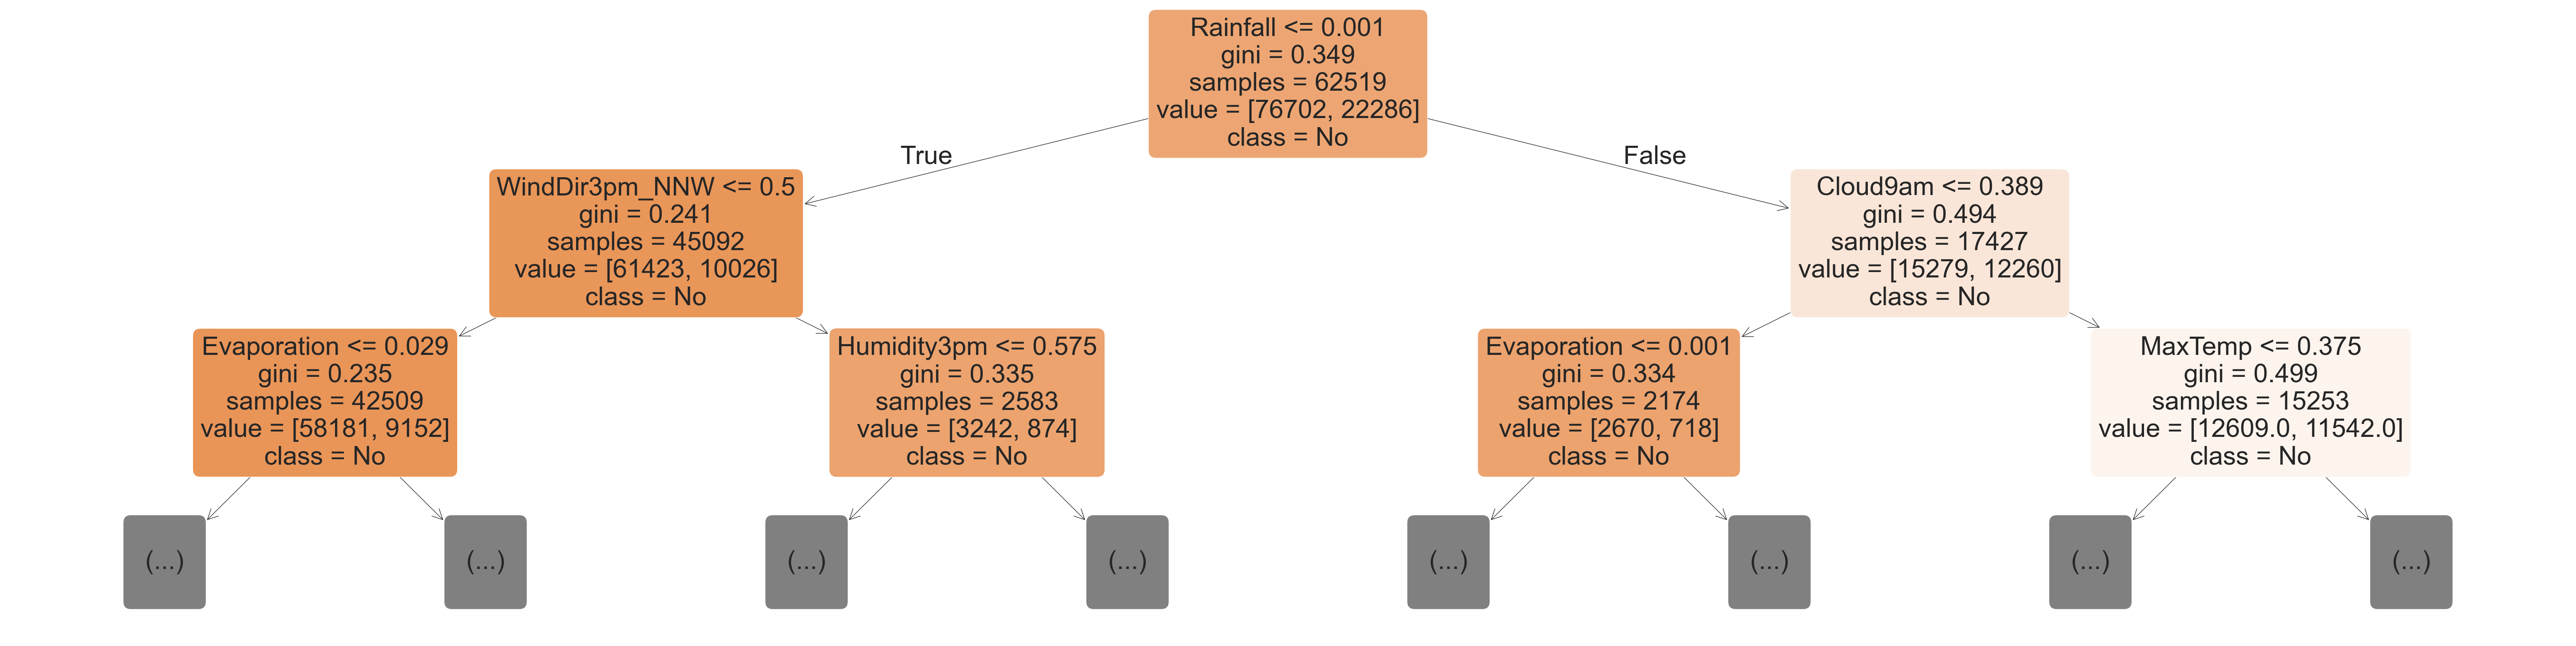

In [93]:
plt.figure(figsize=(80 , 20))
plot_tree(model.estimators_[15] ,max_depth=2 , feature_names=X_train.columns , filled=True ,rounded=True, class_names=model.classes_)

In [94]:
len(model.estimators_)

100

> **EXERCISE:** Verify that none of the individual decision trees have a better validation accuracy than the random forest.

A Random Forest combines predictions from multiple Decision Trees. To verify that ensemble learning improves performance, the validation accuracy of each individual tree was compared with the validation accuracy of the complete Random Forest model.

In [95]:
print(model.classes_)

['No' 'Yes']


In [96]:
from sklearn.metrics import accuracy_score

tree_scores = []

for tree in model.estimators_:

    preds = tree.predict(X_val)

    preds = np.where(preds == 0 , 'No' , 'Yes')


    score = accuracy_score(val_targets, preds)

    tree_scores.append(score)

print("Best Individual Tree Accuracy:", max(tree_scores))
print("Average Tree Accuracy:", np.mean(tree_scores))
print("Random Forest Accuracy:", model.score(X_val, val_targets))

c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
c:\Users\Rohaan farooq\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but DecisionTreeC

Best Individual Tree Accuracy: 0.7913063664325924
Average Tree Accuracy: 0.782920898380825
Random Forest Accuracy: 0.8553189019789914


> **EXERCISE:** Verify that none of the individual decision trees have a better validation accuracy than the random forest.

### Results

| Model | Validation Accuracy |
|---------|---------|
| Best Individual Tree | 79.13% |
| Average Tree Accuracy | 78.29% |
| Random Forest | 85.53% |

### Observations

- The best individual Decision Tree achieved a validation accuracy of **79.13%**.
- The average validation accuracy across all trees was **78.29%**.
- The Random Forest achieved a validation accuracy of **85.53%**.
- None of the individual trees outperformed the Random Forest model.
- The Random Forest improved validation accuracy by approximately **6.4 percentage points** compared to the best individual tree.

### Why Does This Happen?

Each Decision Tree is trained on a different random subset of the data and features. Individual trees are relatively weak learners and may make errors on unseen data.

The Random Forest combines predictions from many trees using majority voting:

1. Each tree makes an independent prediction.
2. The predictions are aggregated.
3. The most common prediction becomes the final output.

This helps reduce variance and improves generalization performance.

### Conclusion

The Random Forest significantly outperformed every individual Decision Tree in the ensemble. This demonstrates the primary advantage of ensemble learning: combining many weak learners to create a stronger and more accurate model.

Just like decision tree, random forests also assign an "importance" to each feature, by combining the importance values from individual trees.

In [97]:
importance_df = pd.DataFrame({
    'feature' : X_train.columns , 
    'importance' : model.feature_importances_
}).sort_values('importance' , ascending = False)

In [98]:
importance_df.head(10)

,feature,importance
9,Humidity3pm,0.148103
2,Rainfall,0.051505
11,Pressure3pm,0.050583
4,Sunshine,0.049154
10,Pressure9am,0.048343
5,WindGustSpeed,0.048144
8,Humidity9am,0.047340
15,Temp3pm,0.045011
1,MaxTemp,0.041530
0,MinTemp,0.041225


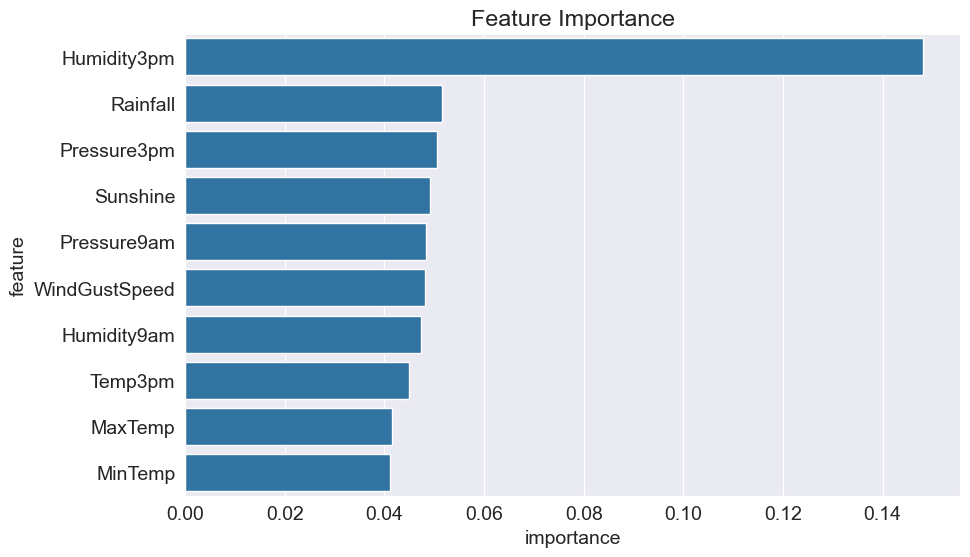

In [99]:
plt.title('Feature Importance')
sns.barplot(data=importance_df.head(10) , x='importance' , y = 'feature');

## Hyperparameter Tuning with Random Forests

Just like Decision Trees, Random Forests also have several hyperparameters that control model complexity, randomness, and generalization performance.

A Random Forest is an ensemble of Decision Trees, so many hyperparameters such as `max_depth`, `min_samples_split`, and `min_samples_leaf` are applied to the individual trees within the forest.

### Important Hyperparameters

- `n_estimators` : Number of trees in the forest.
- `max_depth` : Maximum depth of each tree.
- `max_features` : Number of features considered when searching for the best split.
- `min_samples_split` : Minimum number of samples required to split a node.
- `min_samples_leaf` : Minimum number of samples required in a leaf node.
- `max_leaf_nodes` : Maximum number of leaf nodes allowed in each tree.
- `bootstrap` : Whether bootstrap sampling is used while building trees.

### Goal

The objective of hyperparameter tuning is to find the combination of values that maximizes validation accuracy while avoiding overfitting and maintaining good generalization performance.

> The `n_jobs` parameter controls parallel processing in Random Forests. Setting `n_jobs=-1` uses all available CPU cores to speed up training and prediction.

Let's create a base model with which we can compare models with tuned hyperparameters.

In [100]:
base_model = RandomForestClassifier(random_state=42 , n_jobs = -1).fit(X_train , train_targets)

In [101]:
base_train_acc = base_model.score(X_train , train_targets)
base_val_acc = base_model.score(X_val , val_targets)

In [102]:
base_accs = base_train_acc , base_val_acc
base_accs

(0.9999494888269285, 0.8566537055307295)

### `n_estimators`

This controls the number of decision trees in the random forest. The default value is 100. For larger datasets, it helps to have a greater number of estimators. As a general rule, try to have as few estimators as needed. 


**10 estimators**

In [103]:
model = RandomForestClassifier(random_state=42 , n_jobs=-1,n_estimators=10)

In [104]:
model.fit(X_train , train_targets)

RandomForestClassifier(n_estimators=10, n_jobs=-1, random_state=42)

In [105]:
model.score(X_train , train_targets) , model.score(X_val , val_targets)

(0.986958015112943, 0.8485868492832686)

In [106]:
base_accs

(0.9999494888269285, 0.8566537055307295)

**500 estimators**

In [107]:
model = RandomForestClassifier(random_state=42 , n_jobs=-1 , n_estimators=500)
model.fit(X_train , train_targets)

RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=42)

In [108]:
model.score(X_train , train_targets) , model.score(X_val , val_targets)

(0.9999797955307714, 0.8577563693343393)

In [109]:
base_accs

(0.9999494888269285, 0.8566537055307295)

> **EXERCISE:** Vary the value of `n_estimators` and plot the graph between training error and validation error. What is the optimal value of `n_estimators`?

The `n_estimators` parameter controls the number of Decision Trees in the Random Forest. Increasing the number of trees generally improves model stability and performance, but also increases training time.


In [110]:
def test_n_estimators(n):
    model =RandomForestClassifier(
        n_estimators=n,
        random_state = 42,
        n_jobs=-1
    )
    model.fit(X_train , train_targets)

    train_error = 1- model.score(X_train  , train_targets)
    val_error = 1-model.score(X_val , val_targets)

    return{
        'n_estimator' : n,
        "Training error" : train_error,
        "validation error" : val_error
    }

In [111]:
error_df = pd.DataFrame([test_n_estimators(n) for n in [10 , 20 , 50 , 100 , 200 , 300 , 500]])
error_df

,n_estimator,Training error,validation error
0,10,0.013042,0.151413
1,20,0.003748,0.147293
2,50,0.000354,0.143869
3,100,0.000051,0.143346
4,200,0.000020,0.143811
5,300,0.000020,0.142650
6,500,0.000020,0.142244


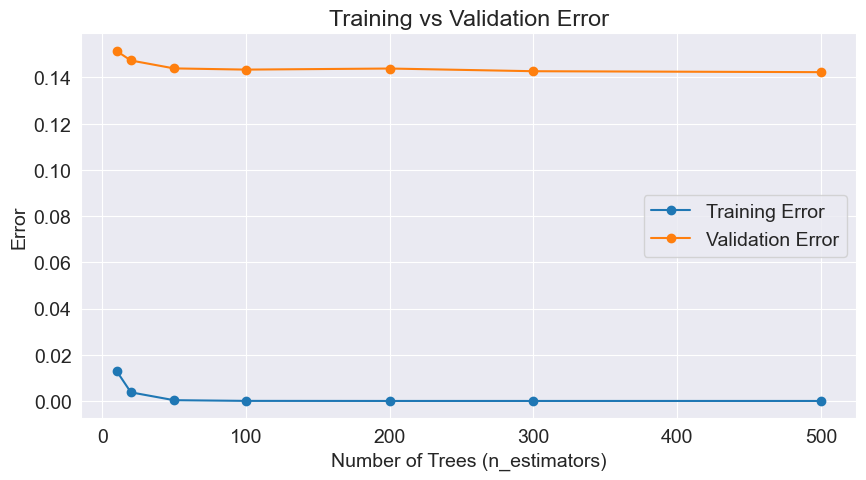

In [112]:
plt.figure(figsize=(10,5))

plt.plot(
    error_df['n_estimator'].to_numpy(),
    error_df['Training error'].to_numpy(),
    marker='o',
    label='Training Error'
)

plt.plot(
    error_df['n_estimator'].to_numpy(),
    error_df['validation error'].to_numpy(),
    marker='o',
    label='Validation Error'
)

plt.xlabel('Number of Trees (n_estimators)')
plt.ylabel('Error')
plt.title('Training vs Validation Error')
plt.legend()

plt.show()

In [113]:
error_df.loc[
    error_df['validation error'].idxmin()
]

n_estimator         500.000000
Training error        0.000020
validation error      0.142244
Name: 6, dtype: float64

> **EXERCISE:** Vary the value of `n_estimators` and plot the graph between training error and validation error. What is the optimal value of `n_estimators`?

### Observations

- As the number of trees increases, the training error decreases steadily.
- The validation error decreases rapidly for smaller values of `n_estimators`.
- After approximately 100 trees, the validation error stabilizes and shows very little improvement.
- Increasing the number of trees beyond this point significantly increases training time while providing only marginal gains in performance.

### Optimal Number of Trees

Based on the validation error curve:

```text
n_estimators = 100

> The validation error decreases as more trees are added, but after about 100 trees the improvement becomes negligible, making `n_estimators = 100` a practical and efficient choice.


________________________________________________________________________________

### `max_features`

Instead of picking all features for every split, we can specify only a fraction of features to be chosen randomly.

<img src="https://i.imgur.com/FXGWMDY.png" width="720">

Notice that the default value `auto` causes only $\sqrt{n}$ out of total features ( $n$ ) to be chosen randomly at each split. This is the reason each decision tree is in the forest is different. While it may seem counterintuitive, choosing all features for every split of every tree will lead to identical trees, so the random forest will not generalize well. 

In [114]:
def test_params(**params):
    model = RandomForestClassifier(random_state=42 , n_jobs=-1 , **params).fit(X_train , train_targets)
    return model.score(X_train , train_targets) , model.score(X_val , val_targets)   

In [115]:
test_params(max_features = 'log2')

(0.9999595910615429, 0.8558992513493123)

In [116]:
test_params(max_features = 3)

(0.9999494888269285, 0.8543323080494458)

In [117]:
test_params(max_features=6)

(0.9999595910615429, 0.8558992513493123)

In [118]:
base_accs

(0.9999494888269285, 0.8566537055307295)

### `max_depth` and `max_leaf_nodes`

These arguments are passed directly to each decision tree, and control the maximum depth and max. no leaf nodes of each tree respectively. By default, no maximum depth is specified, which is why each tree has a training accuracy of 100%. You can specify a `max_depth` to reduce overfitting.

<img src="https://i.imgur.com/EJCrSZw.png" width="480">

Let's define a helper function to `max depth`, `max_leaf_nodes` and other hyperparameters easily.

In [119]:
test_params(max_depth = 5)

(0.8197862367155615, 0.8240961058557251)

In [120]:
test_params(max_depth = 15)

(0.8973107851456742, 0.85195287563113)

In [121]:
test_params(max_depth=25)

(0.9775730391562614, 0.8558992513493123)

In [122]:
test_params(max_leaf_nodes=2**5)

(0.8314341132258456, 0.833904010214149)

In [123]:
test_params(max_leaf_nodes=2**20)

(0.9999595910615429, 0.8568278103418258)

In [124]:
base_accs # no max depth or max leaf nodes

(0.9999494888269285, 0.8566537055307295)

The optimal values of `max_depth` and `max_leaf_nodes` lies somewhere between 0 and unbounded.

In [125]:
for md in [5 , 10 , 15]:
    for mln in [64 , 128 , 256]:
        model = RandomForestClassifier(max_depth=md , max_leaf_nodes=mln , random_state=42 , n_jobs=-1).fit(X_train ,train_targets)
        print(md ,  mln , model.score(X_val  , val_targets) )

5 64 0.8251407347223029
5 128 0.8251407347223029
5 256 0.8251407347223029
10 64 0.8388950147989089
10 128 0.8421449712727062
10 256 0.8437119145725727
15 64 0.838256630491556
15 128 0.8428994254541233
15 256 0.8456851024316638


In [126]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    max_leaf_nodes=256,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, train_targets)

print("Validation Accuracy:", model.score(X_val, val_targets))

Validation Accuracy: 0.8456851024316638


### `min_samples_split` and `min_samples_leaf`

By default, the decision tree classifier tries to split every node that has 2 or more. You can increase the values of these arguments to change this behavior and reduce overfitting, especially for very large datasets.

In [127]:
test_params(min_samples_split=3, min_samples_leaf=2)

(0.9625005051117307, 0.8565956705936975)

In [129]:
test_params(min_samples_split=10, min_samples_leaf=6)

(0.8956439164343153, 0.8548546224827346)

### `min_impurity_decrease`

This argument is used to control the threshold for splitting nodes. A node will be split if this split induces a decrease of the impurity (Gini index) greater than or equal to this value. It's default value is 0, and you can increase it to reduce overfitting.


In [131]:
test_params(min_impurity_decrease = 1e-7)

(0.9996060128500425, 0.8561313910974406)

In [136]:
test_params(min_impurity_decrease = 1e-6)

(0.9888168262819735, 0.8561313910974406)

### `bootstrap`, `max_samples` 

By default, a random forest doesn't use the entire dataset for training each decision tree. Instead it applies a technique called bootstrapping. For each tree, rows from the dataset are picked one by one randomly, with replacement i.e. some rows may not show up at all, while some rows may show up multiple times.


<img src="https://i.imgur.com/W8UGaEA.png" width="640">

Bootstrapping helps the random forest generalize better, because each decision tree only sees a fraction of th training set, and some rows randomly get higher weightage than others.

In [140]:
test_params(bootstrap = False)


(0.9999797955307714, 0.8567697754047937)

In [141]:
base_accs

(0.9999494888269285, 0.8566537055307295)

When bootstrapping is enabled, you can also control the number or fraction of rows to be considered for each bootstrap using `max_samples`. This can further generalize the model.

<img src="https://i.imgur.com/rsdrL1W.png" width="640">

In [143]:
test_params(max_samples = 0.9)

(0.9997676486038711, 0.8565376356566653)

In [144]:
test_params(bootstrap=True, max_samples=None)


(0.9999494888269285, 0.8566537055307295)

In [145]:
test_params(bootstrap=True, max_samples=0.9)


(0.9997676486038711, 0.8565376356566653)

In [146]:
test_params(bootstrap=True, max_samples=0.7)


(0.9949286782236231, 0.8555510417271197)

In [147]:
test_params(bootstrap=False)


(0.9999797955307714, 0.8567697754047937)

In [148]:
model.classes_ 

array(['No', 'Yes'], dtype=object)

In [150]:
test_params(class_weight = 'balanced')

(0.9999595910615429, 0.8553769369160235)

In [151]:
test_params(class_weight = {'No' : 1 , 'Yes' : 2})

(0.9999595910615429, 0.8558412164122802)

In [152]:
weights = [
    None,
    'balanced',
    {'No': 1, 'Yes': 1.5},
    {'No': 1, 'Yes': 2},
    {'No': 1, 'Yes': 2.5},
    {'No': 1, 'Yes': 3}
]

for weight in weights:
    train_score, val_score = test_params(class_weight=weight)
    print(
        f"class_weight={weight}, "
        f"train_score={train_score:.4f}, "
        f"val_score={val_score:.4f}"
    )

class_weight=None, train_score=0.9999, val_score=0.8567
class_weight=balanced, train_score=1.0000, val_score=0.8554
class_weight={'No': 1, 'Yes': 1.5}, train_score=0.9999, val_score=0.8558
class_weight={'No': 1, 'Yes': 2}, train_score=1.0000, val_score=0.8558
class_weight={'No': 1, 'Yes': 2.5}, train_score=1.0000, val_score=0.8564
class_weight={'No': 1, 'Yes': 3}, train_score=1.0000, val_score=0.8529


In [153]:
model.score(X_test , test_targets)

0.8341418341418342

In [157]:
model = RandomForestClassifier(
    n_jobs=-1,
    random_state=42,
    n_estimators=100,
    max_depth=15,
    max_leaf_nodes=256,
    class_weight='balanced'
).fit(X_train , train_targets)

In [159]:
print("Training accuracy:", model.score(X_train, train_targets))
print("Validation accuracy:", model.score(X_val, val_targets))

Training accuracy: 0.8012890451367842
Validation accuracy: 0.803493703209332


In [160]:
from sklearn.metrics import classification_report, confusion_matrix

val_preds = model.predict(X_val)

print(classification_report(val_targets, val_preds))
print("Confusion matrix:")
print(confusion_matrix(val_targets, val_preds))

              precision    recall  f1-score   support

          No       0.92      0.82      0.87     13583
         Yes       0.53      0.74      0.61      3648

    accuracy                           0.80     17231
   macro avg       0.72      0.78      0.74     17231
weighted avg       0.84      0.80      0.81     17231

Confusion matrix:
[[11159  2424]
 [  962  2686]]


In [163]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    max_leaf_nodes=256,
    class_weight={"No": 1, "Yes": 2},
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, train_targets)

print("Training accuracy:", model.score(X_train, train_targets))
print("Validation accuracy:", model.score(X_val, val_targets))

Training accuracy: 0.8488099567624359
Validation accuracy: 0.8435958446985085


In [165]:
import joblib

joblib.dump(model, "rainfall_prediction_model.joblib")

print("Model saved successfully!")

Model saved successfully!
